In [1]:
!pip install pandas numpy matplotlib scikit-learn
import torch
print(torch.__file__)
!pip uninstall -y torch torchsde
!pip install --pre torch --index-url https://download.pytorch.org/whl/nightly/cpu
!pip install torchsde

/opt/miniconda3/lib/python3.14/site-packages/torch/__init__.py
Found existing installation: torch 2.14.0
Uninstalling torch-2.14.0:
  Successfully uninstalled torch-2.14.0
Found existing installation: torchsde 0.2.6
Uninstalling torchsde-0.2.6:
  Successfully uninstalled torchsde-0.2.6
Looking in indexes: https://download.pytorch.org/whl/nightly/cpu
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.6/133.6 MB 14.1 MB/s  0:00:09 eta 0:00:010:0103
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchvision 0.28.0 requires torch==2.13.0, but you have torch 2.15.0.dev20260922 which is incompatible.
  Using cached torchsde-0.2.6-py3-none-any.whl.metadata (5.3 kB)
Using cached torchsde-0.2.6-py3-none-any.whl (61 kB)


In [2]:
import torch
print(torch.__version__)
print(torch.__file__)

2.14.0
/opt/miniconda3/lib/python3.14/site-packages/torch/__init__.py


In [3]:
import datetime as dt
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
import math
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler

import argparse
import logging
import os
import time
import random
from collections import namedtuple
from typing import Optional, Union
import torch
import torch.nn.functional as F
import torch.nn.init as init
from torch import nn, optim, distributions
import torch.backends.cudnn as cudnn
import tqdm
from scipy.stats import levy_stable
import torchsde
#画热图
import seaborn as sns

In [4]:
def setup_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  # no-op on macOS (no CUDA) - harmless, kept for portability
    np.random.seed(seed)
    random.seed(seed)  # uncommented: seeds Python's built-in random module too
    torch.backends.cudnn.deterministic = True  # also a no-op without CUDA - harmless

In [5]:
setup_seed(4)

In [6]:
E1, E2 = cao_method_fast(
    data["close"].values,
    min_m=1,
    max_m=20,
    tau=24
)

print(E1)


NameError: name 'cao_method_fast' is not defined

In [ ]:
import numpy as np
import time

def average_mutual_information(data, max_lag=50, bins=16):
    """
    Average Mutual Information between x_t and x_{t+lag}, for lag = 0..max_lag.
    Used to find a principled time delay tau (first local minimum), per
    Fraser & Swinney (1986) / as used in Strozzi et al.'s Nord Pool analysis.
    """
    data = np.asarray(data, dtype=float).ravel()
    ami = np.zeros(max_lag + 1)
    for lag in range(max_lag + 1):
        if lag == 0:
            x, y = data, data
        else:
            x, y = data[:-lag], data[lag:]
        c_xy, _, _ = np.histogram2d(x, y, bins=bins)
        p_xy = c_xy / np.sum(c_xy)
        p_x = np.sum(p_xy, axis=1)
        p_y = np.sum(p_xy, axis=0)
        nz = p_xy > 0
        px_py = np.outer(p_x, p_y)
        mi = np.sum(p_xy[nz] * np.log(p_xy[nz] / px_py[nz]))
        ami[lag] = mi
    return ami

def first_minimum_ami(ami):
    """First local minimum of AMI -- the standard choice of time delay tau."""
    for i in range(1, len(ami) - 1):
        if ami[i] < ami[i - 1] and ami[i] <= ami[i + 1]:
            return i
    return None  # no local minimum found within max_lag -- see note below

# --- run on your DK2 price differences ---
ami = average_mutual_information(diffs, max_lag=50, bins=16)
tau = first_minimum_ami(ami)
print(f"AMI first minimum -> tau = {tau}")

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(range(len(ami)), ami, '-o')
if tau is not None:
    plt.axvline(tau, color='r', linestyle='--', label=f'first minimum (tau={tau})')
plt.xlabel('Lag')
plt.ylabel('Average Mutual Information')
plt.legend()
plt.grid(True)
plt.title('AMI vs lag (DK2)')
plt.show()

In [19]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

def reconstitution(data, N, m, tau):
    data = np.asarray(data).ravel()
    M = N - (m - 1) * tau
    Y = np.zeros((m, M))
    for i in range(m):
        Y[i, :] = data[i * tau: i * tau + M]
    return Y

def cao_method_fast(data, min_m=1, max_m=30, tau=1):
    data = np.asarray(data, dtype=float).ravel()
    N = len(data)
    E = np.zeros((max_m - min_m + 1, 2))
    En = np.zeros((max_m - min_m + 1, 2))
    k = 0
    for m in range(min_m, max_m + 1):
        Y = reconstitution(data, N, m, tau)
        n_points = N - m * tau
        Ypts = Y[:, :n_points].T

        tree = cKDTree(Ypts)
        dists, idxs = tree.query(Ypts, k=2, p=np.inf)
        D_dist = dists[:, 1]
        D_idx = idxs[:, 1]
        valid = D_dist > 0

        i_arr = np.arange(n_points)
        diff_existing = np.max(np.abs(Ypts - Ypts[D_idx]), axis=1)
        diff_new = np.abs(data[m * tau + i_arr] - data[D_idx + m * tau])
        num = np.maximum(diff_existing, diff_new)

        ad = np.zeros(n_points)
        ad[valid] = num[valid] / D_dist[valid]
        E[k, 0] = m
        E[k, 1] = np.sum(ad) / n_points

        dd = np.abs(data[i_arr + m * tau] - data[D_idx + m * tau])
        En[k, 0] = m
        En[k, 1] = np.sum(dd) / n_points
        k += 1

    n_ratios = max_m - min_m
    E1 = np.zeros((n_ratios, 2))
    E2 = np.zeros((n_ratios, 2))
    for i in range(n_ratios):
        E1[i, 0] = E[i, 0]
        E1[i, 1] = E[i+1, 1] / E[i, 1] if E[i, 1] != 0 else np.nan
        E2[i, 0] = En[i, 0]
        E2[i, 1] = En[i+1, 1] / En[i, 1] if En[i, 1] != 0 else np.nan
    return E1, E2

# --- run on your DK2 price differences, with AMI-selected tau=7 ---
TAU = 7
t0 = time.time()
E1, E2 = cao_method_fast(diffs, min_m=1, max_m=30, tau=TAU)
print(f"took {time.time()-t0:.1f}s")

for row in E1:
    print(f"  m={int(row[0])}: E1={row[1]:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(E1[:, 0], E1[:, 1], '-bs', label='E1(d)')
plt.plot(E2[:, 0], E2[:, 1], '-r*', label='E2(d)')
plt.xlabel('Dimension d')
plt.ylabel('E1(d) & E2(d)')
plt.grid(True)
plt.legend()
plt.title(f"Cao's method (DK2, tau={TAU}, AMI-selected)")
plt.show()


KeyboardInterrupt



In [10]:
# ============================================================
# Load OPSD electricity price data (SE4)
# ============================================================

DATA_PATH = "time_series_60min_singleindex.csv"

TARGET_AREA = "SE4"
TARGET_COLUMN = "SE_4_price_day_ahead"

data = pd.read_csv(DATA_PATH)

data = data[["utc_timestamp", TARGET_COLUMN]].copy()

data.columns = ["date", "close"]

data["code"] = TARGET_AREA
data["open"] = data["close"]
data["high"] = data["close"]
data["low"] = data["close"]
data["volume"] = 0.0

data["close"] = pd.to_numeric(data["close"], errors="coerce")
data = data.dropna(subset=["close"]).reset_index(drop=True)

data["date"] = pd.to_datetime(data["date"], errors="coerce")
data = data.dropna(subset=["date"])

data = (
    data.sort_values("date")
        .drop_duplicates(subset="date", keep="last")
        .reset_index(drop=True)
)

data = data[["date", "code", "open", "close", "high", "low", "volume"]]

print(data.shape)
print("Is sorted:", data["date"].is_monotonic_increasing)

data.head()


(50386, 7)
Is sorted: True


,date,code,open,close,high,low,volume
0,2015-01-01 01:00:00+00:00,SE4,19.33,19.33,19.33,19.33,0.0
1,2015-01-01 02:00:00+00:00,SE4,17.66,17.66,17.66,17.66,0.0
2,2015-01-01 03:00:00+00:00,SE4,17.53,17.53,17.53,17.53,0.0
3,2015-01-01 04:00:00+00:00,SE4,18.07,18.07,18.07,18.07,0.0
4,2015-01-01 05:00:00+00:00,SE4,25.23,25.23,25.23,25.23,0.0


In [7]:
import numpy as np
import pandas as pd
from scipy.stats import levy_stable, norm, kurtosis

# ============================================================
# Load OPSD electricity day-ahead price data
# ============================================================

DATA_PATH = "time_series_60min_singleindex.csv"

# Choose market:
# "DK1" -> "DK_1_price_day_ahead"
# "DK2" -> "DK_2_price_day_ahead"
# "SE4" -> "SE_4_price_day_ahead"
# "NO3" -> "NO_3_price_day_ahead"
# "NO4" -> "NO_4_price_day_ahead"

TARGET_AREA = "NO4"
TARGET_COLUMN = "NO_4_price_day_ahead"

data = pd.read_csv(DATA_PATH)

data = data[["utc_timestamp", TARGET_COLUMN]].copy()

data.columns = ["date", "close"]

data["close"] = pd.to_numeric(data["close"], errors="coerce")

data = data.dropna(subset=["close"]).reset_index(drop=True)

data["date"] = pd.to_datetime(data["date"], errors="coerce")

data = data.dropna(subset=["date"])

data = (
    data.sort_values("date")
        .drop_duplicates(subset="date", keep="last")
        .reset_index(drop=True)
)

prices = data["close"].astype(float).values

r = np.diff(prices)

print(f"{TARGET_AREA}: {len(r)} usable price-difference points")

# ============================================================
# Gaussian fit
# ============================================================

mu_hat, sigma_hat = norm.fit(r)

gauss_ll = np.sum(
    norm.logpdf(r, loc=mu_hat, scale=sigma_hat)
)

# ============================================================
# Alpha-stable fit
# ============================================================

SUBSAMPLE_N = 20000

if SUBSAMPLE_N is None or len(r) <= SUBSAMPLE_N:
    r_fit = r
else:
    rng = np.random.default_rng(0)
    r_fit = rng.choice(r, size=SUBSAMPLE_N, replace=False)

alpha_hat, beta_hat, loc_hat, scale_hat = levy_stable.fit(r_fit)

stable_ll = np.sum(
    levy_stable.logpdf(
        r,
        alpha_hat,
        beta_hat,
        loc=loc_hat,
        scale=scale_hat
    )
)

# ============================================================
# McCulloch-style tail diagnostic
# ============================================================

def mcculloch_alpha(x):
    q = np.percentile(x, [5, 25, 50, 75, 95])
    va = (q[4] - q[0]) / (q[3] - q[1])
    return va

va_check = mcculloch_alpha(r)

# ============================================================
# Excess kurtosis and jump frequency
# ============================================================

excess_kurt = kurtosis(r, fisher=True)

delta_L = stable_ll - gauss_ll

sigma_for_jumps = np.std(r)

jump_freq = np.mean(
    np.abs(r) > 3 * sigma_for_jumps
)

# ============================================================
# Results
# ============================================================

print(f"\n--- {TARGET_AREA} tail-heaviness diagnostics ---")
print(f"alpha_hat (MLE):        {alpha_hat:.4f}")
print(f"beta_hat (skew):        {beta_hat:.4f}")
print(f"McCulloch tail ratio:   {va_check:.4f}")
print(f"Excess kurtosis:        {excess_kurt:.4f}")
print(f"Delta L (stable-Gauss): {delta_L:.2f}")
print(f"Jump frequency (>3sig): {jump_freq:.4%}")

NO4: 50385 usable price-difference points

--- NO4 tail-heaviness diagnostics ---
alpha_hat (MLE):        0.7580
beta_hat (skew):        -0.0835
McCulloch tail ratio:   7.6341
Excess kurtosis:        1252.3943
Delta L (stable-Gauss): 62175.11
Jump frequency (>3sig): 0.9288%


In [10]:
# outlier sanity check
top_outliers = np.sort(np.abs(r))[-20:]
print(top_outliers)

# resampling stability
alphas = []
rng = np.random.default_rng(1)
for _ in range(10):
    sample = rng.choice(r, size=20000, replace=False)
    a, *_ = levy_stable.fit(sample)
    alphas.append(a)
print(np.mean(alphas), np.std(alphas))

[ 94.979996  95.860001  95.960007  95.980003  97.740006  98.020004
  98.539994 100.169998 101.370003 101.909996 109.229995 110.559997
 113.099994 129.559998 137.75     138.259994 143.479996 153.710007
 158.180008 172.450004]


KeyboardInterrupt: 

In [12]:
import numpy as np
from scipy.stats import levy_stable
import time

# do NOT set pdf_default_method to 'fft' or 'fft-simpson' — unstable/buggy
# for heavy-tailed (alpha near 1) data on this scipy version

scale0 = (np.percentile(r, 75) - np.percentile(r, 25)) / 1.654
loc0 = np.median(r)

levy_stable.pdf_default_method = 'piecewise'  # override any leftover 'fft' setting

alphas = []
rng = np.random.default_rng(1)
for i in range(5):
    t0 = time.time()
    sample = rng.choice(r, size=1000, replace=False)  # keep this small — see benchmark
    a, b, loc_, scale_ = levy_stable.fit(sample, 1.0, 0.0, floc=loc0, fscale=scale0)
    print(i, "alpha:", a, f"({time.time()-t0:.1f}s)", flush=True)
    alphas.append(a)

print("mean:", np.mean(alphas), "std:", np.std(alphas))

0 alpha: 1.0329417046246803 (24.7s)
1 alpha: 0.9541341885942527 (22.0s)
2 alpha: 0.9949507623910898 (34.3s)
3 alpha: 1.0320400908589464 (31.1s)
4 alpha: 0.9949978967546481 (34.3s)
mean: 1.0018129286447235 std: 0.029152969892245632


In [15]:
# ============================================================
# Build stk_data from OPSD dataset
# ============================================================

stk_data = data.copy()

stk_data["Open"] = stk_data["close"]
stk_data["High"] = stk_data["close"]
stk_data["Low"] = stk_data["close"]
stk_data["Close"] = stk_data["close"]

stk_data = stk_data.rename(columns={"date": "Date"})

stk_data = stk_data[
    ["Date", "Open", "High", "Low", "Close"]
].copy()

stk_data = (
    stk_data.sort_values("Date")
            .reset_index(drop=True)
)

# ============================================================
# Proportional train/test split
# ============================================================

TEST_FRACTION = 0.2

n_rows = len(stk_data)

split_idx = int(n_rows * (1 - TEST_FRACTION))

SPLIT_DATE = stk_data["Date"].iloc[split_idx]

# ------------------------------------------------------------
# PRICE LEVELS
# ------------------------------------------------------------

price_mask_train = stk_data["Date"] < SPLIT_DATE
price_mask_test = stk_data["Date"] >= SPLIT_DATE

training_set = (
    stk_data.loc[price_mask_train, "Close"]
            .values
            .reshape(-1, 1)
)

testing_set = (
    stk_data.loc[price_mask_test, "Close"]
            .values
            .reshape(-1, 1)
)

print(f"Split date: {SPLIT_DATE}")

print(
    f"[Price Levels] Training: {len(training_set)} rows "
    f"({stk_data.loc[price_mask_train,'Date'].min()} "
    f"to {stk_data.loc[price_mask_train,'Date'].max()})"
)

print(
    f"[Price Levels] Testing: {len(testing_set)} rows "
    f"({stk_data.loc[price_mask_test,'Date'].min()} "
    f"to {stk_data.loc[price_mask_test,'Date'].max()})"
)

print(
    f"[Price Levels] Training range: "
    f"{training_set.min():.2f} to {training_set.max():.2f}"
)

print(
    f"[Price Levels] Testing range: "
    f"{testing_set.min():.2f} to {testing_set.max():.2f}"
)

# ============================================================
# Scaling
# ============================================================

from sklearn.preprocessing import StandardScaler
import numpy as np

scaler = StandardScaler()

# TRAINING DATA ONLY
training_set_scaled = scaler.fit_transform(training_set)

# Apply same scaler to test data
testing_set_scaled = scaler.transform(testing_set)

# ------------------------------------------------------------
# Patch inverse_transform so 1D arrays work everywhere
# ------------------------------------------------------------
_orig_inverse = scaler.inverse_transform

def _patched_inverse(X, *args, **kwargs):
    X = np.asarray(X)

    was_1d = (X.ndim == 1)

    if was_1d:
        X = X.reshape(-1, 1)

    out = _orig_inverse(X, *args, **kwargs)

    if was_1d:
        out = out.flatten()

    return out

scaler.inverse_transform = _patched_inverse

training_dates = (
    stk_data.loc[price_mask_train, "Date"]
            .reset_index(drop=True)
)

testing_dates = (
    stk_data.loc[price_mask_test, "Date"]
            .reset_index(drop=True)
)

training_set_scaled3 = pd.DataFrame({
    "Date": training_dates.values,
    "closescale": training_set_scaled.flatten()
})

testing_set_scaled3 = pd.DataFrame({
    "Date": testing_dates.values,
    "closescale": testing_set_scaled.flatten()
})

print(
    f"[Price Levels] Test mean relative to train: "
    f"{(testing_set.mean() - training_set.mean()) / training_set.std():.2f} std devs"
)

# ============================================================
# PRICE DIFFERENCES
# ============================================================

prices_all = stk_data["Close"].astype(float).values

diffs_all = np.diff(prices_all).reshape(-1, 1)

return_dates_all = (
    pd.to_datetime(
        stk_data["Date"].iloc[1:]
    ).reset_index(drop=True)
)

n_diffs = len(diffs_all)

split_idx_diffs = int(
    n_diffs * (1 - TEST_FRACTION)
)

DIFF_SPLIT_DATE = return_dates_all.iloc[split_idx_diffs]

diff_train_mask = (
    return_dates_all < DIFF_SPLIT_DATE
)

diff_test_mask = (
    return_dates_all >= DIFF_SPLIT_DATE
)

training_set_returns = diffs_all[
    diff_train_mask.values
]

testing_set_returns = diffs_all[
    diff_test_mask.values
]

training_dates_returns = (
    return_dates_all[diff_train_mask]
    .reset_index(drop=True)
)

testing_dates_returns = (
    return_dates_all[diff_test_mask]
    .reset_index(drop=True)
)

print(f"\n[Price Diffs] Split date: {DIFF_SPLIT_DATE}")

print(
    f"[Price Diffs] Training: {training_set_returns.shape}"
)

print(
    f"[Price Diffs] Testing: {testing_set_returns.shape}"
)

print(
    f"[Price Diffs] Training range: "
    f"{training_set_returns.min():.4f} "
    f"to {training_set_returns.max():.4f}"
)

print(
    f"[Price Diffs] Testing range: "
    f"{testing_set_returns.min():.4f} "
    f"to {testing_set_returns.max():.4f}"
)

# ============================================================
# Difference scaling
# ============================================================

scaler_returns = StandardScaler()

# TRAINING DATA ONLY
scaler_returns.fit(training_set_returns)

training_set_scaled_returns = (
    scaler_returns.transform(
        training_set_returns
    )
)

testing_set_scaled_returns = (
    scaler_returns.transform(
        testing_set_returns
    )
)

# ------------------------------------------------------------
# Patch inverse_transform so train()/test() plotting works
# ------------------------------------------------------------
_orig_returns_inverse = scaler_returns.inverse_transform

def _patched_returns_inverse(X, *args, **kwargs):
    X = np.asarray(X)

    was_1d = (X.ndim == 1)

    if was_1d:
        X = X.reshape(-1, 1)

    out = _orig_returns_inverse(X, *args, **kwargs)

    if was_1d:
        out = out.flatten()

    return out

scaler_returns.inverse_transform = _patched_returns_inverse

print(
    f"[Price Diffs] Scaled training range: "
    f"{training_set_scaled_returns.min():.4f} "
    f"to {training_set_scaled_returns.max():.4f}"
)

print(
    f"[Price Diffs] Scaled testing range: "
    f"{testing_set_scaled_returns.min():.4f} "
    f"to {testing_set_scaled_returns.max():.4f}"
)

training_set_scaled3_returns = pd.DataFrame({
    "Date": training_dates_returns.values,
    "closescale": training_set_scaled_returns.flatten()
})

testing_set_scaled3_returns = pd.DataFrame({
    "Date": testing_dates_returns.values,
    "closescale": testing_set_scaled_returns.flatten()
})

# ------------------------------------------------------------
# Quick sanity check
# ------------------------------------------------------------
print("\nScaler test:")

x = np.array([1, 2, 3])

try:
    scaler_returns.inverse_transform(x)
    print("PASS: 1D inverse_transform works")
except Exception as e:
    print("FAIL:", e)

Split date: 2019-08-07 23:00:00+00:00
[Price Levels] Training: 40308 rows (2015-01-01 01:00:00+00:00 to 2019-08-07 22:00:00+00:00)
[Price Levels] Testing: 10078 rows (2019-08-07 23:00:00+00:00 to 2020-09-30 22:00:00+00:00)
[Price Levels] Training range: 1.38 to 255.02
[Price Levels] Testing range: 0.00 to 80.75
[Price Levels] Test mean relative to train: -0.99 std devs

[Price Diffs] Split date: 2019-08-08 00:00:00+00:00
[Price Diffs] Training: (40308, 1)
[Price Diffs] Testing: (10077, 1)
[Price Diffs] Training range: -138.2600 to 158.1800
[Price Diffs] Testing range: -17.8300 to 38.1900
[Price Diffs] Scaled training range: -55.6968 to 63.7212
[Price Diffs] Scaled testing range: -7.1827 to 15.3844

Scaler test:
PASS: 1D inverse_transform works


# Data Cleaning and Splitting

In [16]:
print('Training set shape:', training_set.shape, '\n', 'Testing set shape:', testing_set.shape)

Training set shape: (40308, 1) 
 Testing set shape: (10078, 1)


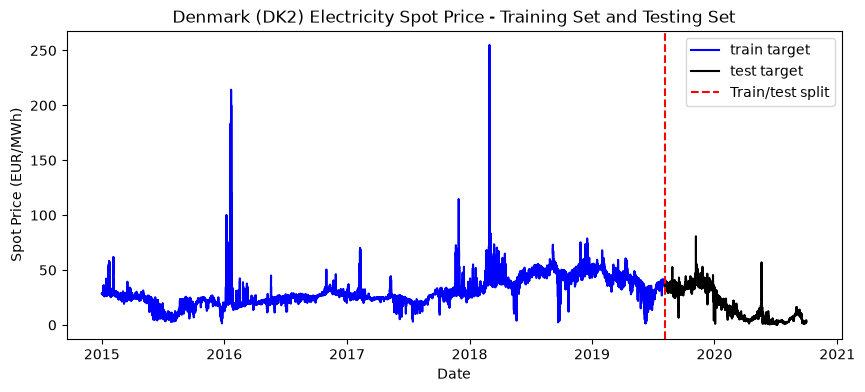

In [17]:
# show predictions
plt.figure(figsize=(10, 4))
plt.plot(training_dates, training_set, color='blue', label='train target')
plt.plot(testing_dates, testing_set, color='black', label='test target')
plt.axvline(pd.Timestamp(SPLIT_DATE), color='red', linestyle='--', label='Train/test split')
plt.title('Denmark (DK2) Electricity Spot Price - Training Set and Testing Set')
plt.xlabel('Date')
plt.ylabel('Spot Price (EUR/MWh)')
plt.legend(loc='best')
plt.show()

# 利用相空间重构方法创建数据

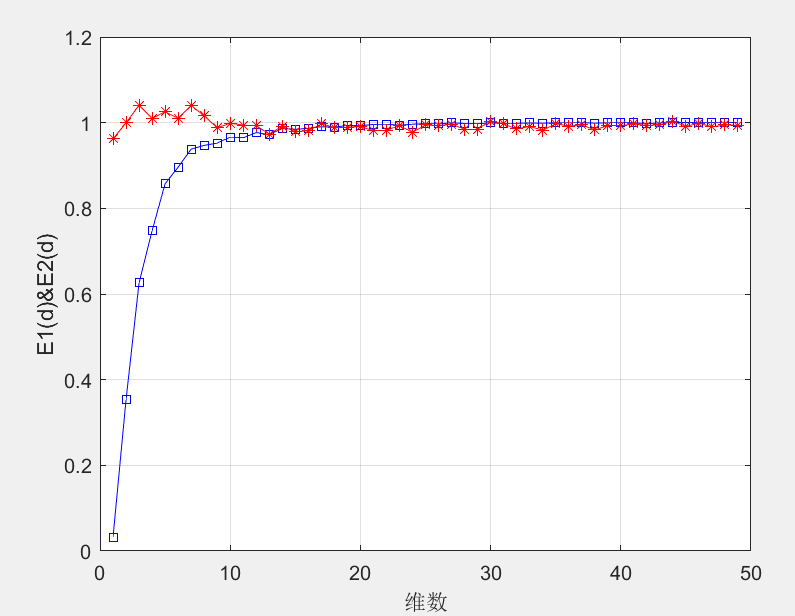

相空间重构数据

In [18]:
# Overwrite the stale price-level names with the correct log-return
# versions, so PhaSpaRecon (and everything after it) uses the right data.
training_set_scaled3 = training_set_scaled3_returns
testing_set_scaled3 = testing_set_scaled3_returns

print("testing_set_scaled3 now:", len(testing_set_scaled3), "rows,",
      testing_set_scaled3['Date'].min(), "to", testing_set_scaled3['Date'].max(),
      "NaN count:", testing_set_scaled3['closescale'].isna().sum())

testing_set_scaled3 now: 10077 rows, 2019-08-08 00:00:00 to 2020-09-30 22:00:00 NaN count: 0


In [19]:
# data为时间序列，tau为重构的时延，d为重构的维数，T为直接预测的步数
def PhaSpaRecon(df,tau,d,T):
    data = np.array(df)[:, 1]
    date = np.array(df)[:, 0]
    lens = len(data)
    if (lens - T - (d-1) * tau) < 1:
        print("error: delay time or the embedding dimension is too large")
    else:
        Xn1 = np.zeros((d, lens-(d-1)*tau-1))
        for i in range(0, d):
            Xn1[i, :] = data[i*tau:i*tau+lens-(d-1)*tau-1]
            # for j in range(i*tau, i*tau+lens-(d-1)*tau-1):
            #     Xn[i, j] = data[j]
        Yn1 = data[(T+(d-1)*tau):T+(d-1)*tau+lens-(d-1)*tau-1]
        Yn1_date = date[(T+(d-1)*tau):T+(d-1)*tau+lens-(d-1)*tau-1]
        Yn = Yn1.reshape((len(Yn1), 1))
        Yn_date = Yn1_date.reshape((len(Yn1_date), 1))
        Yn = pd.DataFrame(Yn)
        Yn_date = pd.DataFrame(Yn_date)
        Y = pd.concat([Yn_date, Yn],axis=1)
        Xn = Xn1.T #reshape((Xn1.shape[1], Xn1.shape[0]))
        Xn = pd.DataFrame(Xn)
        X = pd.concat([Xn, Yn],axis=1)
    return Xn, Yn, Y, X

In [20]:
Xn, Yn,Y,X = PhaSpaRecon(training_set_scaled3, tau=1, d=12, T=1)

In [21]:
Xn

,0,1,2,3,4,5,6,7,8,9,10,11
0,-0.016188,0.003954,0.048267,0.128835,0.036182,-0.004102,0.007983,0.003954,0.012011,0.016040,0.012011,0.020068
1,0.003954,0.048267,0.128835,0.036182,-0.004102,0.007983,0.003954,0.012011,0.016040,0.012011,0.020068,0.020068
2,0.048267,0.128835,0.036182,-0.004102,0.007983,0.003954,0.012011,0.016040,0.012011,0.020068,0.020068,-0.048415
3,0.128835,0.036182,-0.004102,0.007983,0.003954,0.012011,0.016040,0.012011,0.020068,0.020068,-0.048415,-0.012159
4,0.036182,-0.004102,0.007983,0.003954,0.012011,0.016040,0.012011,0.020068,0.020068,-0.048415,-0.012159,-0.012159
...,...,...,...,...,...,...,...,...,...,...,...,...
40291,0.221488,0.012011,-0.008131,-0.008131,-0.261920,0.181204,-0.104812,-0.133011,-0.020216,-0.000074,-0.028273,-0.020216
40292,0.012011,-0.008131,-0.008131,-0.261920,0.181204,-0.104812,-0.133011,-0.020216,-0.000074,-0.028273,-0.020216,-0.004102
40293,-0.008131,-0.008131,-0.261920,0.181204,-0.104812,-0.133011,-0.020216,-0.000074,-0.028273,-0.020216,-0.004102,-0.036330
40294,-0.008131,-0.261920,0.181204,-0.104812,-0.133011,-0.020216,-0.000074,-0.028273,-0.020216,-0.004102,-0.036330,-0.628505


In [22]:
train= X.values
x_train1=train[:,0:12]
y_train1=train[:,12]

In [23]:
X1n, Y1n, Y1,X1 = PhaSpaRecon(testing_set_scaled3, tau=1, d=12, T=1)

In [24]:
test= X1.values
x_test1=test[:,0:12]
y_test1=test[:,12]

In [25]:
print('x_train1 shape:', x_train1.shape, '\n', 'x_test1 shape:', x_test1.shape, '\n', 'y_train1 shape:', y_train1.shape, '\n', 'y_test1 shape:', y_test1.shape)

x_train1 shape: (40296, 12) 
 x_test1 shape: (10065, 12) 
 y_train1 shape: (40296,) 
 y_test1 shape: (10065,)


In [26]:
ts_  = np.arange(0, y_train1.shape[0])
ts_ext_ = np.arange(y_train1.shape[0], y_train1.shape[0] + y_test1.shape[0])
ts_full_ = np.arange(0, y_train1.shape[0] + y_test1.shape[0])

In [27]:
# Since each year has 252 trading days on average
ts_ = ts_/252; ts_ext_ = ts_ext_/252; ts_full_ = ts_full_/252 # ts_[-1] = 4.44444, ts_ext_[-1] : 5.5555

print('ts_ shape:', ts_.shape, '\n', 'ts_ext_ shape:', ts_ext_.shape, '\n', 'ts_full_ shape:', ts_full_.shape)

ts_ shape: (40296,) 
 ts_ext_ shape: (10065,) 
 ts_full_ shape: (50361,)


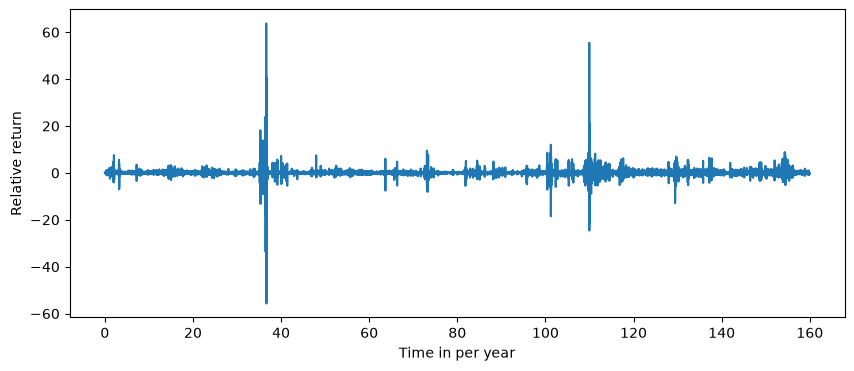

In [28]:
plt.figure(figsize = (10,4))
plt.plot(ts_, y_train1)
plt.xlabel('Time in per year')
plt.ylabel('Relative return')
plt.show()

In [29]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
xs_ = x_train1.astype(np.float64)
ys_ = y_train1.astype(np.float64)
xs_ext_ = x_test1.astype(np.float64)
ys_ext_ = y_test1.astype(np.float64)#object转float
xs = torch.tensor(xs_).float().to(device)
ys = torch.tensor(ys_).float().to(device)
# ys = ys.view(y_train.shape[0],1)
xs_ext = torch.tensor(xs_ext_).float().to(device)
ys_ext = torch.tensor(ys_ext_).float().to(device)

ts = torch.tensor(ts_).float().to(device)
ts = ts.view(ts_.shape[0],1)
ts_ext = torch.tensor(ts_ext_).float().to(device)
ts_ext = ts_ext.view(ts_ext_.shape[0],1)
ts_vis = ts_ext

In [30]:
Data = namedtuple('Data', ['ts_', 'ts_ext_', 'ts_vis_', 'ts', 'ts_ext', 'ts_vis', 'ys', 'ys_','ys_ext_'])

In [31]:
X21n, Y21n,Y21,X21 = PhaSpaRecon(training_set_scaled3, tau=1, d=12, T=2)
X22n, Y22n, Y22,X22 = PhaSpaRecon(testing_set_scaled3, tau=1, d=12, T=2)

In [32]:
train2= X21.values
train2=np.delete(train2,-1, axis=0)#减一是因为预测第二天T=2
x_train2=train2[:,0:12]
y_train2=train2[:,12]
test2= X22.values
test2=np.delete(test2,-1, axis=0)#减一是因为预测第二天T=2
x_test2=test2[:,0:12]
y_test2=test2[:,12]

In [33]:
X31n, Y31n,Y31,X31 = PhaSpaRecon(training_set_scaled3, tau=1, d=12, T=3)
X32n, Y32n, Y32,X32 = PhaSpaRecon(testing_set_scaled3, tau=1, d=12, T=3)

In [34]:
train3= X31.values
train3=np.delete(train3,[-1,-2], axis=0)#减一是因为预测第二天T=3
x_train3=train3[:,0:12]
y_train3=train3[:,12]
test3= X32.values
test3=np.delete(test3,[-1,-2], axis=0)#减一是因为预测第二天T=3
x_test3=test3[:,0:12]
y_test3=test3[:,12]

In [35]:
X41n, Y41n,Y41,X41 = PhaSpaRecon(training_set_scaled3, tau=1, d=12, T=4)
X42n, Y42n, Y42,X42 = PhaSpaRecon(testing_set_scaled3, tau=1, d=12, T=4)

In [36]:
train4= X41.values
train4=np.delete(train4,[-1,-2,-3], axis=0)#减一是因为预测第二天T=4
x_train4=train4[:,0:12]
y_train4=train4[:,12]
test4= X42.values
test4=np.delete(test4,[-1,-2,-3], axis=0)#减一是因为预测第二天T=4
x_test4=test4[:,0:12]
y_test4=test4[:,12]

# SDE Definition

In [37]:
sequence_length: int = 12
alpha, beta = 1.5, 0

In [38]:
__all__ = ['SDENet1']

class Drift1(nn.Module):
    def __init__(self):
        super(Drift1, self).__init__()
        self.fc = nn.Linear(sequence_length, sequence_length)          #线性层（全连接）
        self.relu = nn.ReLU(inplace=True)   #inplace = True 时,会修改输入对象的值,所以打印出对象存储地址相同，max(0,x)
    def forward(self, t, x):
        out = self.relu(self.fc(x))
        return out    



class Diffusion1(nn.Module):
    def __init__(self):
        super(Diffusion1, self).__init__()#super(Net, self).__init__()是指首先找到Net的父类（比如是类NNet），然后把类Net的对象self转换为类NNet的对象，然后“被转换”的类NNet对象调用自己的init函数
        self.relu = nn.ReLU(inplace=True)
        self.fc1 = nn.Linear(sequence_length, 100)
        self.fc2 = nn.Linear(100, 1)
    def forward(self, t, x):
        out = self.relu(self.fc1(x))
        out = self.fc2(out)
        out = torch.sigmoid(out)
        return out


    
class SDENet1(nn.Module):
    def __init__(self, layer_depth):
        super(SDENet1, self).__init__()
        self.layer_depth = layer_depth
        self.downsampling_layers = nn.Linear(sequence_length,sequence_length)
        self.drift = Drift1()
        self.diffusion = Diffusion1()
        self.deltat = 1./self.layer_depth
        self.sigma = 0.5
    def forward(self, x, training_diffusion=False):
        out = self.downsampling_layers(x)
        if not training_diffusion:     #如果training_diffusion是假的执行下面的程序
            t = 0
            diffusion_term = self.sigma*self.diffusion(t, out)
            for i in range(self.layer_depth):
                t = (float(i))/self.layer_depth
                out = out + self.drift(t, out)*self.deltat + diffusion_term*(self.deltat**(1/alpha))*torch.from_numpy(levy_stable.rvs(alpha, beta, size=sequence_length,scale=0.1)).to(x)####
            Out1=out
            Drift1=self.drift(t, out)
            return Drift1,Out1
            
        else:
            t = 0
            final_out1 = self.diffusion(t, out.detach())  
            return final_out1

def test():
    model = SDENet1(layer_depth=6)
    return model  
 
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

if __name__ == '__main__':
    model1 = test()
    num_params = count_parameters(model1)
    print(num_params)

1713


In [39]:
__all__ = ['SDENet2']

class Drift2(nn.Module):
    def __init__(self):
        super(Drift2, self).__init__()
        self.fc = nn.Linear(sequence_length, sequence_length)          #线性层（全连接）
        self.relu = nn.ReLU(inplace=True)   #inplace = True 时,会修改输入对象的值,所以打印出对象存储地址相同，max(0,x)
    def forward(self, t, x):
        out = self.relu(self.fc(x))
        return out    



class Diffusion2(nn.Module):
    def __init__(self):
        super(Diffusion2, self).__init__()#super(Net, self).__init__()是指首先找到Net的父类（比如是类NNet），然后把类Net的对象self转换为类NNet的对象，然后“被转换”的类NNet对象调用自己的init函数
        self.relu = nn.ReLU(inplace=True)
        self.fc1 = nn.Linear(sequence_length, 100)
        self.fc2 = nn.Linear(100, 1)
    def forward(self, t, x):
        out = self.relu(self.fc1(x))
        out = self.fc2(out)
        out = torch.sigmoid(out)
        return out


    
class SDENet2(nn.Module):
    def __init__(self, layer_depth):
        super(SDENet2, self).__init__()
        self.layer_depth = layer_depth
        self.downsampling_layers = nn.Linear(sequence_length,sequence_length)
        self.drift = Drift2()
        self.diffusion = Diffusion2()
        self.deltat = 1./self.layer_depth
        self.sigma = 0.5
    def forward(self, x, training_diffusion=False):
        out = self.downsampling_layers(x)
#        Out1=Out1.detach().numpy()#减一是因为预测后一天T=1和T=2差一天
#        Out1=np.delete(Out1,-1, axis=0)
#        Out1=torch.from_numpy(Out1)
#        out=torch.cat((out,Out1), 1)
        if not training_diffusion:     #如果training_diffusion是假的执行下面的程序
            t = 0
            diffusion_term = self.sigma*self.diffusion(t, out)
            for i in range(self.layer_depth):
                t = (float(i))/self.layer_depth
                out = out + self.drift(t, out)*self.deltat + diffusion_term*(self.deltat**(1/alpha))*torch.from_numpy(levy_stable.rvs(alpha, beta, size=sequence_length,scale=0.1)).to(x)####
            Out2=out
            Drift2=self.drift(t, out)
            return Drift2,Out2
            
        else:
            t = 0
            final_out2 = self.diffusion(t, out.detach())  
            return final_out2

def test():
    model2 = SDENet2(layer_depth=6)
    return model2  
 
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

if __name__ == '__main__':
    model2 = test()
    num_params = count_parameters(model2)
    print(num_params)

1713


In [40]:
__all__ = ['SDENet3']

class Drift3(nn.Module):
    def __init__(self):
        super(Drift3, self).__init__()
        self.fc = nn.Linear(sequence_length, sequence_length)          #线性层（全连接）
        self.relu = nn.ReLU(inplace=True)   #inplace = True 时,会修改输入对象的值,所以打印出对象存储地址相同，max(0,x)
    def forward(self, t, x):
        out = self.relu(self.fc(x))
        return out    



class Diffusion3(nn.Module):
    def __init__(self):
        super(Diffusion3, self).__init__()#super(Net, self).__init__()是指首先找到Net的父类（比如是类NNet），然后把类Net的对象self转换为类NNet的对象，然后“被转换”的类NNet对象调用自己的init函数
        self.relu = nn.ReLU(inplace=True)
        self.fc1 = nn.Linear(sequence_length, 100)
        self.fc2 = nn.Linear(100, 1)
    def forward(self, t, x):
        out = self.relu(self.fc1(x))
        out = self.fc2(out)
        out = torch.sigmoid(out)
        return out


    
class SDENet3(nn.Module):
    def __init__(self, layer_depth):
        super(SDENet3, self).__init__()
        self.layer_depth = layer_depth
        self.downsampling_layers = nn.Linear(sequence_length,sequence_length)
        self.drift = Drift3()
        self.diffusion = Diffusion3()
        self.deltat = 1./self.layer_depth
        self.sigma = 0.5
    def forward(self, x, training_diffusion=False):
        out = self.downsampling_layers(x)
#        Out2=Out2.detach().numpy()#减一是因为预测后一天T=2和T=3差一天
#        Out2=np.delete(Out2,-1, axis=0)
#        Out2=torch.from_numpy(Out2)
#        out=torch.cat((out,Out2), 1)
        if not training_diffusion:     #如果training_diffusion是假的执行下面的程序
            t = 0
            diffusion_term = self.sigma*self.diffusion(t, out)
            for i in range(self.layer_depth):
                t = (float(i))/self.layer_depth
                out = out + self.drift(t, out)*self.deltat + diffusion_term*(self.deltat**(1/alpha))*torch.from_numpy(levy_stable.rvs(alpha, beta, size=sequence_length,scale=0.1)).to(x)####
            Out3=out
            Drift3=self.drift(t, out)
            return Drift3,Out3
            
        else:
            t = 0
            final_out3 = self.diffusion(t, out.detach())  
            return final_out3

def test():
    model3 = SDENet3(layer_depth=6)
    return model3  
 
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

if __name__ == '__main__':
    model3 = test()
    num_params = count_parameters(model3)
    print(num_params)

1713


In [41]:
__all__ = ['SDENet4']

class Drift4(nn.Module):
    def __init__(self):
        super(Drift4, self).__init__()
        self.fc = nn.Linear(sequence_length, sequence_length)          #线性层（全连接）
        self.relu = nn.ReLU(inplace=True)   #inplace = True 时,会修改输入对象的值,所以打印出对象存储地址相同，max(0,x)
    def forward(self, t, x):
        out = self.relu(self.fc(x))
        return out    



class Diffusion4(nn.Module):
    def __init__(self):
        super(Diffusion4, self).__init__()#super(Net, self).__init__()是指首先找到Net的父类（比如是类NNet），然后把类Net的对象self转换为类NNet的对象，然后“被转换”的类NNet对象调用自己的init函数
        self.relu = nn.ReLU(inplace=True)
        self.fc1 = nn.Linear(sequence_length, 100)
        self.fc2 = nn.Linear(100, 1)
    def forward(self, t, x):
        out = self.relu(self.fc1(x))
        out = self.fc2(out)
        out = torch.sigmoid(out)
        return out


    
class SDENet4(nn.Module):
    def __init__(self, layer_depth):
        super(SDENet4, self).__init__()
        self.layer_depth = layer_depth
        self.downsampling_layers = nn.Linear(sequence_length,sequence_length)
        self.drift = Drift4()
        self.diffusion = Diffusion4()
#        self.fc_layers = nn.Sequential(nn.ReLU(inplace=True), nn.Linear(sequence_length, 8))#将激活层与线性层连接一起
        self.deltat = 1./self.layer_depth
        self.sigma = 0.5
    def forward(self, x, training_diffusion=False):
        out = self.downsampling_layers(x)
#        Out3=Out3.detach().numpy()#减一是因为预测后一天T=2和T=3差一天
#        Out3=np.delete(Out3,-1, axis=0)
#        Out3=torch.from_numpy(Out3)
#        out=torch.cat((out,Out3), 1)
        if not training_diffusion:     #如果training_diffusion是假的执行下面的程序
            t = 0
            diffusion_term = self.sigma*self.diffusion(t, out)
            for i in range(self.layer_depth):
                t = (float(i))/self.layer_depth
                out = out + self.drift(t, out)*self.deltat + diffusion_term*(self.deltat**(1/alpha))*torch.from_numpy(levy_stable.rvs(alpha, beta, size=sequence_length,scale=0.1)).to(x)####
            Out4=out
            Drift4=self.drift(t, out)
#            final_out4 = self.fc_layers(out) 
#            mean41 = final_out[:,0]
#            mean42 = final_out[:,1]
#            mean43 = final_out[:,2]
#            mean44 = final_out[:,3]
#            sigma41 = F.softplus(final_out[:,5])+1e-3
#            sigma42 = F.softplus(final_out[:,6])+1e-3
#            sigma43 = F.softplus(final_out[:,7])+1e-3
#            sigma44 = F.softplus(final_out[:,8])+1e-3
            return Drift4,Out4
            
        else:
            t = 0
            final_out4 = self.diffusion(t, out.detach())  
            return final_out4

def test():
    model4 = SDENet4(layer_depth=6)
    return model4  
 
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

if __name__ == '__main__':
    model4 = test()
    num_params = count_parameters(model4)
    print(num_params)

1713


# SDE_Regression

DataSet loading

In [42]:
X_train1 = torch.from_numpy(x_train1.astype(np.float64)).float()
X_test1 = torch.from_numpy(x_test1.astype(np.float64)).float()
Y_train1 = torch.from_numpy(y_train1.astype(np.float64)).float()
Y_test1 = torch.from_numpy(y_test1.astype(np.float64)).float()
print('X_train1.shape:', X_train1.shape, '\nX_test1.shape:', X_test1.shape, '\nY_train1.shape:', Y_train1.shape, '\nY_test1.shape:', Y_test1.shape)

X_train1.shape: torch.Size([40296, 12]) 
X_test1.shape: torch.Size([10065, 12]) 
Y_train1.shape: torch.Size([40296]) 
Y_test1.shape: torch.Size([10065])


In [43]:
X_train2 = torch.from_numpy(x_train2.astype(np.float64)).float()
X_test2 = torch.from_numpy(x_test2.astype(np.float64)).float()
Y_train2 = torch.from_numpy(y_train2.astype(np.float64)).float()
Y_test2 = torch.from_numpy(y_test2.astype(np.float64)).float()
print('X_train2.shape:', X_train2.shape, '\nX_test2.shape:', X_test2.shape, '\nY_train2.shape:', Y_train2.shape, '\nY_test2.shape:', Y_test2.shape)

X_train2.shape: torch.Size([40295, 12]) 
X_test2.shape: torch.Size([10064, 12]) 
Y_train2.shape: torch.Size([40295]) 
Y_test2.shape: torch.Size([10064])


In [44]:
X_train3 = torch.from_numpy(x_train3.astype(np.float64)).float()
X_test3 = torch.from_numpy(x_test3.astype(np.float64)).float()
Y_train3 = torch.from_numpy(y_train3.astype(np.float64)).float()
Y_test3 = torch.from_numpy(y_test3.astype(np.float64)).float()
print('X_train3.shape:', X_train3.shape, '\nX_test3.shape:', X_test3.shape, '\nY_train3.shape:', Y_train3.shape, '\nY_test3.shape:', Y_test3.shape)

X_train3.shape: torch.Size([40294, 12]) 
X_test3.shape: torch.Size([10063, 12]) 
Y_train3.shape: torch.Size([40294]) 
Y_test3.shape: torch.Size([10063])


In [45]:
X_train4 = torch.from_numpy(x_train4.astype(np.float64)).float()
X_test4 = torch.from_numpy(x_test4.astype(np.float64)).float()
Y_train4 = torch.from_numpy(y_train4.astype(np.float64)).float()
Y_test4 = torch.from_numpy(y_test4.astype(np.float64)).float()
print('X_train4.shape:', X_train4.shape, '\nX_test4.shape:', X_test4.shape, '\nY_train4.shape:', Y_train4.shape, '\nY_test4.shape:', Y_test4.shape)

X_train4.shape: torch.Size([40293, 12]) 
X_test4.shape: torch.Size([10062, 12]) 
Y_train4.shape: torch.Size([40293]) 
Y_test4.shape: torch.Size([10062])


Arguments

In [46]:
from __future__ import print_function

parser = argparse.ArgumentParser(description='PyTorch SDENet Training')
parser.add_argument('--epochs', type=int, default=100, help='number of epochs to train')
parser.add_argument('--lr', default=1e-4, type=float, help='learning rate')
parser.add_argument('--lr2', default=0.01, type=float, help='learning rate')
parser.add_argument('--gpu', type=int, default=0)
parser.add_argument('--seed', type=float, default=0)
parser.add_argument('--droprate', type=float, default=0.1, help='learning rate decay')
parser.add_argument('--decreasing_lr', default=[20], nargs='+', help='decreasing strategy')
parser.add_argument('--decreasing_lr2', default=[], nargs='+', help='decreasing strategy')

args = parser.parse_args([])
print(args)
device = torch.device('cuda:' + str(args.gpu) if torch.cuda.is_available() else 'cpu')

batch_size1 = y_train1.squeeze().shape[0]
batch_size2 = y_train2.squeeze().shape[0]
batch_size3 = y_train3.squeeze().shape[0]
batch_size4 = y_train4.squeeze().shape[0]
Iter = 50
Iter_test = 1

Namespace(epochs=100, lr=0.0001, lr2=0.01, gpu=0, seed=0, droprate=0.1, decreasing_lr=[20], decreasing_lr2=[])


# Model

In [47]:
!pip uninstall torch -y
!pip install torch==2.14.0 --break-system-packages

Found existing installation: torch 2.15.0.dev20260922
Uninstalling torch-2.15.0.dev20260922:
  Successfully uninstalled torch-2.15.0.dev20260922
  Using cached torch-2.14.0-cp314-cp314-macosx_14_0_arm64.whl.metadata (39 kB)
Using cached torch-2.14.0-cp314-cp314-macosx_14_0_arm64.whl (127.3 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchvision 0.28.0 requires torch==2.13.0, but you have torch 2.14.0 which is incompatible.


In [48]:
import torch, torchsde
print(torch.__version__)

2.14.0


In [49]:
from sklearn.metrics import mean_squared_error
net1 = SDENet1(25)
net1 = net1.to(device)
net2 = SDENet2(25)
net2 = net2.to(device)
net3 = SDENet3(25)
net3 = net3.to(device)
net4 = SDENet4(25)
net4 = net4.to(device)
attention = nn.Sequential(nn.ReLU(inplace=True), nn.Linear(4*sequence_length, 14))
criterion = nn.BCELoss()

real_label = 0
fake_label = 1
optimizer_F = optim.SGD([ {'params': net1.downsampling_layers.parameters()}, {'params': net1.drift.parameters()},{'params': net2.downsampling_layers.parameters()},{'params': net2.drift.parameters()},{'params': net3.downsampling_layers.parameters()},{'params': net3.drift.parameters()} ,{'params': net4.downsampling_layers.parameters()},{'params': net4.drift.parameters()},{'params': attention.parameters()}], lr=args.lr, momentum=0.9, weight_decay=5e-4)
optimizer_G = optim.SGD([ {'params': net1.diffusion.parameters()},{'params': net2.diffusion.parameters()},{'params': net3.diffusion.parameters()},{'params': net4.diffusion.parameters()}], lr=args.lr2, momentum=0.9, weight_decay=5e-4)

def nll_loss(y, mean, sigma):
    loss = torch.mean(torch.log(sigma**2)+(y-mean)**2/(sigma**2))
    return loss
def mse(y, mean):
    loss = torch.mean((y-mean)**2)
    return loss

# Training
def train(epoch):
    print('\nEpoch: %d' % epoch)
    net1.train()
    net2.train()
    net3.train()
    net4.train()
    train_loss = 0
    train_loss_in = 0
    train_loss_out = 0
    total = 0
    for iternum in range(Iter):
        inputs1, targets1 = X_train1, Y_train1[0:-3]
        inputs2, targets2 = X_train2, Y_train2[0:-2]
        inputs3, targets3 = X_train3, Y_train3[0:-1]
        inputs4, targets4 = X_train4, Y_train4
        inputs1, targets1 = inputs1.to(device), targets1.to(device)
        inputs2, targets2 = inputs2.to(device), targets2.to(device)
        inputs3, targets3 = inputs3.to(device), targets3.to(device)
        inputs4, targets4 = inputs4.to(device), targets4.to(device)
        optimizer_F.zero_grad()
        Drift1,Out1 = net1(inputs1)
        Drift2,Out2 = net2(inputs2)
        Drift3,Out3 = net3(inputs3)
        Drift4,Out4 = net4(inputs4)
        Out=torch.cat([Out1[0:-3,:],Out2[0:-2,:],Out3[0:-1,:],Out4],1)
        final_out=attention(Out)
        mean41 = final_out[:,0]
        mean42 = final_out[:,1]
        mean43 = final_out[:,2]
        mean44 = final_out[:,3]
        sigma41 = F.softplus(final_out[:,4])+1e-3
        sigma42 = F.softplus(final_out[:,5])+1e-3
        sigma43 = F.softplus(final_out[:,6])+1e-3
        sigma44 = F.softplus(final_out[:,7])+1e-3
        loss1 = nll_loss(targets1, mean41, sigma41)
        loss2 = nll_loss(targets2, mean42, sigma42)
        loss3 = nll_loss(targets3, mean43, sigma43)
        loss4 = nll_loss(targets4, mean44, sigma44)
        loss=loss1+loss2+loss3+loss4
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            [p for g in optimizer_F.param_groups for p in g['params']], max_norm=5.0
        )
        optimizer_F.step()
        train_loss += loss.item()

        label1 = torch.full((batch_size1,1), real_label, device=device)
        label2 = torch.full((batch_size2,1), real_label, device=device)
        label3 = torch.full((batch_size3,1), real_label, device=device)
        label4 = torch.full((batch_size4,1), real_label, device=device)
        optimizer_G.zero_grad()
        predict_in1 = net1(inputs1, training_diffusion=True)
        predict_in2 = net2(inputs2, training_diffusion=True)
        predict_in3 = net3(inputs3, training_diffusion=True)
        predict_in4 = net4(inputs4, training_diffusion=True)
        loss_in = criterion(predict_in1, label1.float())+criterion(predict_in2, label2.float())+criterion(predict_in3, label3.float())+criterion(predict_in4, label4.float())
        loss_in.backward()
        label1.fill_(fake_label)
        label2.fill_(fake_label)
        label3.fill_(fake_label)
        label4.fill_(fake_label)

        inputs_out1 = 2 * torch.randn(batch_size1, sequence_length, device = device) + inputs1
        inputs_out2 = 2 * torch.randn(batch_size2, sequence_length, device = device) + inputs2
        inputs_out3 = 2 * torch.randn(batch_size3, sequence_length, device = device) + inputs3
        inputs_out4 = 2 * torch.randn(batch_size4, sequence_length, device = device) + inputs4
        predict_out1 = net1(inputs_out1, training_diffusion=True)
        predict_out2 = net2(inputs_out2, training_diffusion=True)
        predict_out3 = net3(inputs_out3, training_diffusion=True)
        predict_out4 = net4(inputs_out4, training_diffusion=True)
        loss_out = criterion(predict_out1, label1.float())+criterion(predict_out2, label2.float())+criterion(predict_out3, label3.float())+criterion(predict_out4, label4.float())

        loss_out.backward()
        train_loss_out += loss_out.item()
        train_loss_in += loss_in.item()
        optimizer_G.step()

    plt.figure(1,figsize = (5, 4))
    plt.plot(np.array(range(len(ts_[0:-3]))), scaler_returns.inverse_transform(mean41.cpu().detach().numpy()),label = 'prediction(t+1)')
    plt.fill_between(np.array(range(len(ts_[0:-3]))),scaler_returns.inverse_transform(mean41.cpu().detach().numpy())+np.sqrt(scaler_returns.inverse_transform(sigma41.cpu().detach().numpy())), scaler_returns.inverse_transform(mean41.cpu().detach().numpy())-np.sqrt(scaler_returns.inverse_transform(sigma41.cpu().detach().numpy())), facecolor='green', edgecolor='red', alpha=0.3)
    plt.plot(np.array(range(len(ts_[0:-3]))), scaler_returns.inverse_transform(targets1.cpu().detach().numpy()),label = 'truth(t+1)')
    plt.legend()
    plt.figure(2,figsize = (5, 4))
    plt.plot(np.array(range(len(ts_[0:-3]))), scaler_returns.inverse_transform(mean42.cpu().detach().numpy()),label = 'prediction(t+2)')
    plt.fill_between(np.array(range(len(ts_[0:-3]))),scaler_returns.inverse_transform(mean42.cpu().detach().numpy())+np.sqrt(scaler_returns.inverse_transform(sigma42.cpu().detach().numpy())), scaler_returns.inverse_transform(mean42.cpu().detach().numpy())-np.sqrt(scaler_returns.inverse_transform(sigma42.cpu().detach().numpy())), facecolor='green', edgecolor='red', alpha=0.3)
    plt.plot(np.array(range(len(ts_[0:-3]))), scaler_returns.inverse_transform(targets2.cpu().detach().numpy()),label = 'truth(t+2)')
    plt.legend()
    plt.figure(3,figsize = (5, 4))
    plt.plot(np.array(range(len(ts_[0:-3]))), scaler_returns.inverse_transform(mean43.cpu().detach().numpy()),label = 'prediction(t+3)')
    plt.fill_between(np.array(range(len(ts_[0:-3]))),scaler_returns.inverse_transform(mean43.cpu().detach().numpy())+np.sqrt(scaler_returns.inverse_transform(sigma43.cpu().detach().numpy())), scaler_returns.inverse_transform(mean43.cpu().detach().numpy())-np.sqrt(scaler_returns.inverse_transform(sigma43.cpu().detach().numpy())), facecolor='green', edgecolor='red', alpha=0.3)
    plt.plot(np.array(range(len(ts_[0:-3]))), scaler_returns.inverse_transform(targets3.cpu().detach().numpy()),label = 'truth(t+3)')
    plt.legend()
    plt.figure(4,figsize = (5, 4))
    plt.plot(np.array(range(len(ts_[0:-3]))), scaler_returns.inverse_transform(mean44.cpu().detach().numpy()),label = 'prediction(t+4)')
    plt.fill_between(np.array(range(len(ts_[0:-3]))),scaler_returns.inverse_transform(mean44.cpu().detach().numpy())+np.sqrt(scaler_returns.inverse_transform(sigma44.cpu().detach().numpy())), scaler_returns.inverse_transform(mean44.cpu().detach().numpy())-np.sqrt(scaler_returns.inverse_transform(sigma44.cpu().detach().numpy())), facecolor='green', edgecolor='red', alpha=0.3)
    plt.plot(np.array(range(len(ts_[0:-3]))), scaler_returns.inverse_transform(targets4.cpu().detach().numpy()),label = 'truth(t+4)')
    img_path = os.path.join(path, f'train_{epoch}.png')
    plt.savefig(img_path, dpi = 300)
    plt.legend()
    plt.show()
    loss11=mean_squared_error(Y_train1.numpy()[0:-3], mean41.cpu().detach().numpy())
    loss22=mean_squared_error(Y_train2.numpy()[0:-2], mean42.cpu().detach().numpy())
    loss33=mean_squared_error(Y_train3.numpy()[0:-1], mean43.cpu().detach().numpy())
    loss44=mean_squared_error(Y_train4.numpy(), mean44.cpu().detach().numpy())
    print('Train epoch:{} \tLoss: {:.6f}| Loss_in: {:.6f}| Loss_out: {:.6f}'.format(epoch, train_loss/Iter, train_loss_in/Iter, train_loss_out/Iter))
    return loss11,loss22,loss33,loss44

In [50]:
# Testing
def test(epoch):
    net1.eval()
    net2.eval()
    net3.eval()
    net4.eval()
    test_loss = 0
    total = 0
    with torch.no_grad():
        for iternum in range(Iter_test):
            inputs1, targets1 = X_test1, Y_test1[0:-3]
            inputs2, targets2 = X_test2, Y_test2[0:-2]
            inputs3, targets3 = X_test3, Y_test3[0:-1]
            inputs4, targets4 = X_test4, Y_test4
            inputs1, targets1 = inputs1.to(device), targets1.to(device)
            inputs2, targets2 = inputs2.to(device), targets2.to(device)
            inputs3, targets3 = inputs3.to(device), targets3.to(device)
            inputs4, targets4 = inputs4.to(device), targets4.to(device)
            current_mean1 = 0
            current_mean2 = 0
            current_mean3 = 0
            current_mean4 = 0
            current_sigma1 = 0
            current_sigma2 = 0
            current_sigma3 = 0
            current_sigma4 = 0
            for i in range(1):
                #mean, sigma ,Drift= net(inputs)
                Drift1,Out1 = net1(inputs1)
                Drift2,Out2 = net2(inputs2)
                Drift3,Out3 = net3(inputs3)
                Drift4,Out4 = net4(inputs4)
                Out=torch.cat([Out1[0:-3,:],Out2[0:-2,:],Out3[0:-1,:],Out4],1)
                final_out=attention(Out)
                mean41 = final_out[:,0]
                mean42 = final_out[:,1]
                mean43 = final_out[:,2]
                mean44 = final_out[:,3]
                sigma41 = F.softplus(final_out[:,4])+1e-3
                sigma42 = F.softplus(final_out[:,5])+1e-3
                sigma43 = F.softplus(final_out[:,6])+1e-3
                sigma44 = F.softplus(final_out[:,7])+1e-3 
                current_mean1 = current_mean1 + mean41
                current_mean2 = current_mean2 + mean42
                current_mean3 = current_mean3 + mean43
                current_mean4 = current_mean4 + mean44
                current_sigma1= current_sigma1+ sigma41
                current_sigma2= current_sigma2+ sigma42
                current_sigma3= current_sigma3+ sigma43
                current_sigma4= current_sigma4+ sigma44
            current_mean1 = current_mean1/1
            current_mean2 = current_mean2/1
            current_mean3 = current_mean3/1
            current_mean4 = current_mean4/1
            current_sigma1 = current_sigma1/1
            current_sigma2 = current_sigma2/1
            current_sigma3 = current_sigma3/1
            current_sigma4 = current_sigma4/1            
            loss1 = mse(targets1, current_mean1)
            loss2 = mse(targets2, current_mean2)
            loss3 = mse(targets3, current_mean3)
            loss4 = mse(targets4, current_mean4)
            loss=loss1+loss2+loss3+loss4
#            plt.figure(figsize = (8, 4))
#            plt.subplot(221)
            plt.figure(1,figsize = (5, 3))
            plt.plot(np.array(range(len(ts_ext_[0:-3]))), scaler_returns.inverse_transform(current_mean1.cpu().detach().numpy()),label = 'prediction(t+1)')
#             plt.fill_between(np.array(range(len(ts_ext_[0:-3]))),scaler_returns.inverse_transform(current_mean1.cpu().detach().numpy())+np.sqrt(scaler_returns.inverse_transform(current_sigma1.cpu().detach().numpy())), 
#                              scaler_returns.inverse_transform(current_mean1.cpu().detach().numpy())-np.sqrt(scaler_returns.inverse_transform(current_sigma1.cpu().detach().numpy())),facecolor='green', edgecolor='red', alpha=0.3)
            plt.plot(np.array(range(len(ts_ext_[0:-3]))), scaler_returns.inverse_transform(targets1.cpu().detach().numpy()),label = 'truth(t+1)')
            plt.legend()
#            plt.subplot(222)
            plt.figure(2,figsize = (5, 3))
            plt.plot(np.array(range(len(ts_ext_[0:-3]))), scaler_returns.inverse_transform(current_mean2.cpu().detach().numpy()),label = 'prediction(t+2)')
#             plt.fill_between(np.array(range(len(ts_ext_[0:-3]))),scaler_returns.inverse_transform(current_mean2.cpu().detach().numpy())+np.sqrt(scaler_returns.inverse_transform(current_sigma2.cpu().detach().numpy())), 
#                              scaler_returns.inverse_transform(current_mean2.cpu().detach().numpy())-np.sqrt(scaler_returns.inverse_transform(current_sigma2.cpu().detach().numpy())),facecolor='green', edgecolor='red', alpha=0.3)
            plt.plot(np.array(range(len(ts_ext_[0:-3]))), scaler_returns.inverse_transform(targets2.cpu().detach().numpy()),label = 'truth(t+2)')
            plt.legend()
#            plt.subplot(223)
            plt.figure(3,figsize = (5, 3))
            plt.plot(np.array(range(len(ts_ext_[0:-3]))), scaler_returns.inverse_transform(current_mean3.cpu().detach().numpy()),label = 'prediction(t+3)')
#             plt.fill_between(np.array(range(len(ts_ext_[0:-3]))),scaler_returns.inverse_transform(current_mean3.cpu().detach().numpy())+np.sqrt(scaler_returns.inverse_transform(current_sigma3.cpu().detach().numpy())), 
#                              scaler_returns.inverse_transform(current_mean3.cpu().detach().numpy())-np.sqrt(scaler_returns.inverse_transform(current_sigma3.cpu().detach().numpy())),facecolor='green', edgecolor='red', alpha=0.3)
            plt.plot(np.array(range(len(ts_ext_[0:-3]))), scaler_returns.inverse_transform(targets3.cpu().detach().numpy()),label = 'truth(t+3)')
            plt.legend()
#            plt.subplot(224)
            plt.figure(4,figsize = (5, 3))
            plt.plot(np.array(range(len(ts_ext_[0:-3]))), scaler_returns.inverse_transform(current_mean4.cpu().detach().numpy()),label = 'prediction(t+4)')
#             plt.fill_between(np.array(range(len(ts_ext_[0:-3]))),scaler_returns.inverse_transform(current_mean4.cpu().detach().numpy())+np.sqrt(scaler_returns.inverse_transform(current_sigma4.cpu().detach().numpy())), 
#                              scaler_returns.inverse_transform(current_mean4.cpu().detach().numpy())-np.sqrt(scaler_returns.inverse_transform(current_sigma4.cpu().detach().numpy())),facecolor='green', edgecolor='red', alpha=0.3)
            plt.plot(np.array(range(len(ts_ext_[0:-3]))), scaler_returns.inverse_transform(targets4.cpu().detach().numpy()),label = 'truth(t+4)')
            img_path = os.path.join(path, f'test_{epoch}.png')
            
            plt.savefig(img_path, dpi = 300)
            plt.legend()
            plt.show()
            test_loss += loss.item()
    
            loss11 = mean_squared_error(Y_test1.numpy()[0:-3], current_mean1.cpu().detach().numpy()) 
            loss22 = mean_squared_error(Y_test2.numpy()[0:-2], current_mean2.cpu().detach().numpy())
            loss33 = mean_squared_error(Y_test3.numpy()[0:-1], current_mean3.cpu().detach().numpy())
            loss44 = mean_squared_error(Y_test4.numpy(), current_mean4.cpu().detach().numpy())
    print('Test epoch:{} \tLoss: {:.6f}'.format(epoch, np.sqrt(test_loss/Iter_test)))
    return loss11,loss22,loss33,loss44
    #return loss11, current_mean1.cpu().detach().numpy()), mean_squared_error(Y_test2.numpy()[0:-2], current_mean2.cpu().detach().numpy()),mean_squared_error(Y_test3.numpy()[0:-1], current_mean3.cpu().detach().numpy()),mean_squared_error(Y_test4.numpy(), current_mean4.cpu().detach().numpy())
    #return mean_squared_error(Y_test3.numpy()[0:-1], current_mean3.cpu().detach().numpy())

# Run Epochs

In [51]:
import numpy as np

x = np.array([1,2,3])

try:
    y = scaler_returns.inverse_transform(x)
    print("WORKS")
    print(y[:3])
except Exception as e:
    print("FAILED")
    print(e)

WORKS
[2.48255536 4.96492714 7.44729892]



Epoch: 1


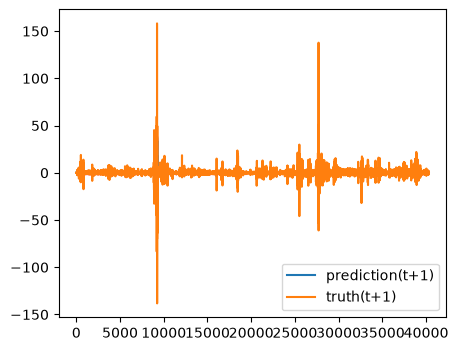

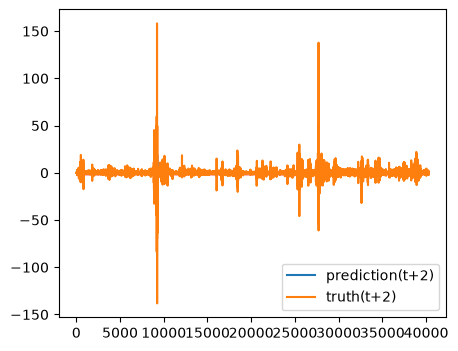

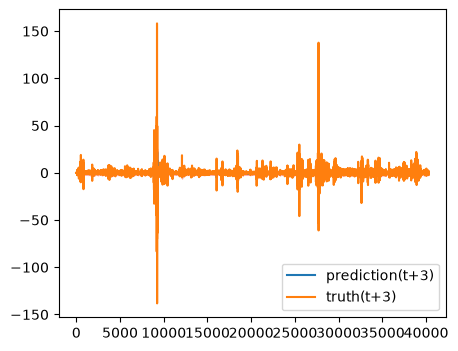

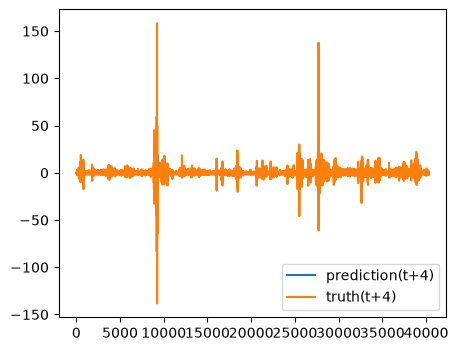

Train epoch:1 	Loss: 129946.107344| Loss_in: 2.765902| Loss_out: 1.412622


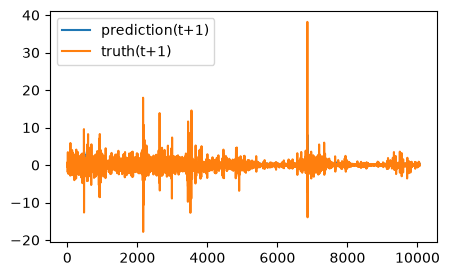

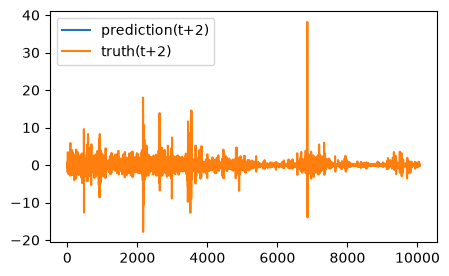

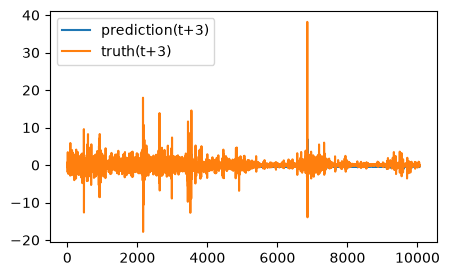

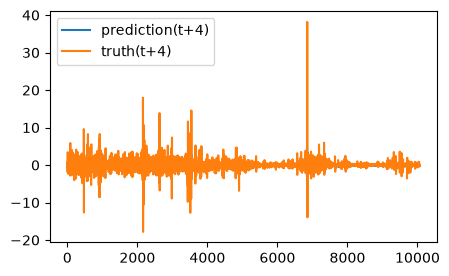

Test epoch:1 	Loss: 0.953482

Epoch: 2


KeyboardInterrupt: 

In [52]:
path = os.path.join(os.getcwd(), 'output')
os.makedirs(path, exist_ok=True)

train_losses = []
test_losses = []
for epoch in range(1, args.epochs + 1):
    train_losses.append(train(epoch))
    test_losses.append(test(epoch))
    if epoch in args.decreasing_lr:
        for param_group in optimizer_F.param_groups:
            param_group['lr'] *= args.droprate
    if epoch in args.decreasing_lr2:
        for param_group in optimizer_G.param_groups:
            param_group['lr'] *= args.droprate

In [143]:
print('x_test1.shape:', x_test1.shape, 'y_test1.shape:', y_test1.shape)
print('x_test2.shape:', x_test2.shape, 'y_test2.shape:', y_test2.shape)
print('x_test3.shape:', x_test3.shape, 'y_test3.shape:', y_test3.shape)
print('x_test4.shape:', x_test4.shape, 'y_test4.shape:', y_test4.shape)

x_test1.shape: (10065, 12) y_test1.shape: (10065,)
x_test2.shape: (10064, 12) y_test2.shape: (10064,)
x_test3.shape: (10063, 12) y_test3.shape: (10063,)
x_test4.shape: (10062, 12) y_test4.shape: (10062,)


In [144]:
test_losses

[(1.7126802206039429,
  1.6950469017028809,
  2.0035109519958496,
  1.9367425441741943),
 (1.691633701324463,
  1.6776474714279175,
  1.9161231517791748,
  1.9011837244033813),
 (1.6343389749526978,
  1.6236072778701782,
  1.7827224731445312,
  1.8475463390350342),
 (1.611609935760498, 1.599748969078064, 1.7113144397735596, 1.794042944908142),
 (1.5855259895324707,
  1.5860280990600586,
  1.6748634576797485,
  1.755048394203186),
 (1.5675327777862549,
  1.571824550628662,
  1.6455482244491577,
  1.7408937215805054),
 (1.5465489625930786,
  1.5606693029403687,
  1.6419997215270996,
  1.693626046180725),
 (1.536510705947876,
  1.5579167604446411,
  1.6063822507858276,
  1.6947712898254395),
 (1.5284333229064941,
  1.5495998859405518,
  1.5946534872055054,
  1.6632697582244873),
 (1.514654517173767,
  1.5432747602462769,
  1.5839195251464844,
  1.6468359231948853),
 (1.5059499740600586,
  1.5399516820907593,
  1.5657169818878174,
  1.6394115686416626),
 (1.4993245601654053,
  1.5341994762

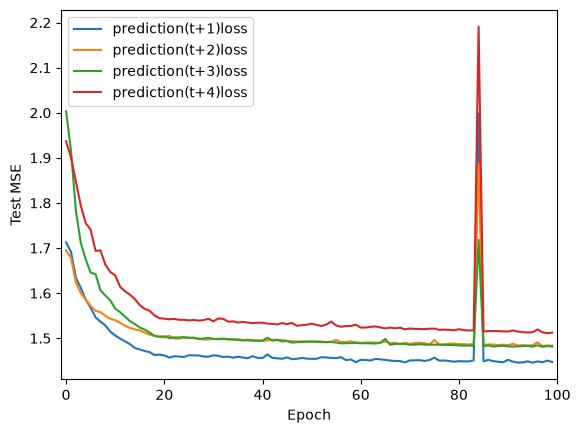

In [145]:
plt.plot(test_losses)
plt.xlim(-1, args.epochs)   # was hardcoded to 12; now matches your actual 100-epoch run
plt.xlabel('Epoch')
plt.ylabel('Test MSE')
plt.legend(('prediction(t+1)loss','prediction(t+2)loss','prediction(t+3)loss','prediction(t+4)loss'))
plt.show()

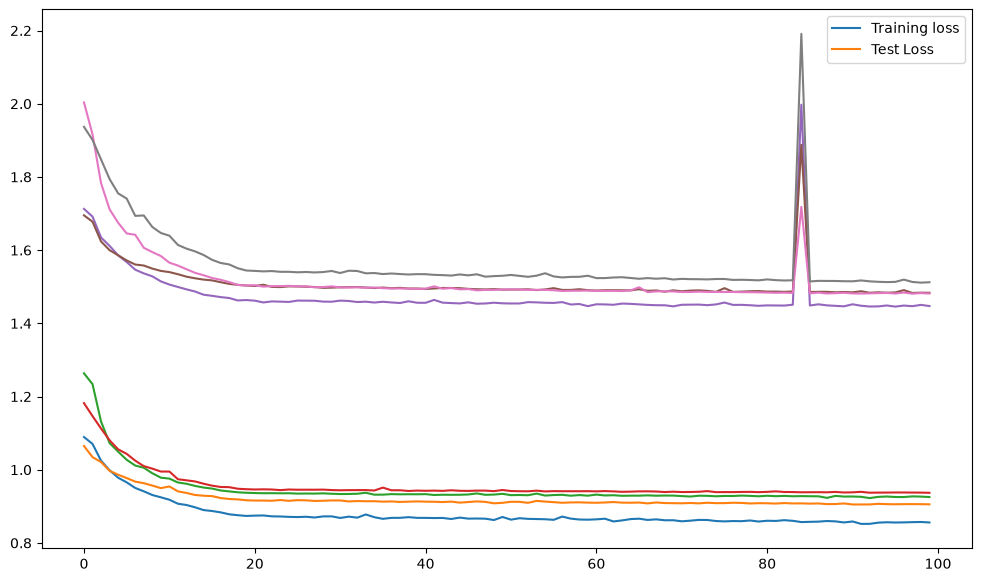

(1.4472548961639404, 1.4834905862808228, 1.48140287399292, 1.5122826099395752)


In [146]:
plt.figure(figsize=(12,7))
plt.plot(train_losses)
plt.plot(test_losses)
plt.legend(('Training loss','Test Loss'))
plt.savefig(os.path.join(path, 'Loss'), dpi=300)
plt.show()
print(test_losses[-1])

In [147]:
type(np.array(range(10)))

numpy.ndarray

In [148]:
print("Var(y_test1):", np.var(y_test1))
print("Var(y_test2):", np.var(y_test2))
print("Var(y_test3):", np.var(y_test3))
print("Var(y_test4):", np.var(y_test4))

Var(y_test1): 1.6398957220932484
Var(y_test2): 1.640056797726228
Var(y_test3): 1.6402193855172198
Var(y_test4): 1.6403812398221087


In [54]:
# ============================================================
# T=1 SINGLE-HORIZON COMPARISON: Zero, ARIMA, LSTM, LDE-Net (Levy,
# alpha=1.5), SDE-Net (Gaussian, alpha=2.0) — Denmark DK1 electricity
# spot price differences. Matches the original paper's Experiment 2
# design ("since one-hour-ahead accuracy is highest, we only compare
# the effect of forecasting one hour ahead").
#
# LDE-Net here = a STANDALONE single-horizon SDENet1 (the real class
# from cell 40, alpha=1.5 Levy noise), trained alone with its own
# NLL+BCE objective - NOT the four-network attention-fused net1-4
# system. This uses ONLY the T=1 embedding, exactly like every other
# model in this table.
#
# SDE-Net Gaussian = identical architecture, alpha=2.0 instead of
# 1.5, trained the SAME way (same NLL+BCE scheme, same epochs) - a
# genuinely fair Levy-vs-Gaussian comparison, isolating alpha with
# everything else held fixed.
#
# Reviewer response: this cell also runs a direct, paired
# Diebold-Mariano test between LDE-Net and Gaussian SDE-Net (not
# just each vs. the zero baseline), since that is the comparison the
# paper's core Levy-vs-Gaussian claim actually rests on. It also
# reports DM tests of both neural models against the zero baseline
# explicitly, including cases where zero wins, rather than only
# emphasising wins.
#
# Requires: x_train1/y_train1/x_test1/y_test1 (T=1 data),
# sequence_length, training_set_scaled3/testing_set_scaled3
# already defined earlier in the notebook.
# ============================================================

import numpy as np
import pandas as pd
import math
import random

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from scipy.stats import levy_stable, t as t_dist
from sklearn.metrics import mean_squared_error, mean_absolute_error

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEEDS = [0, 1, 2, 3, 4]


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def smape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    return 100 * np.mean(2*np.abs(y_pred-y_true)/(np.abs(y_true)+np.abs(y_pred)+eps))


def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    mse = mean_squared_error(y_true, y_pred)
    return {"MSE": mse, "RMSE": math.sqrt(mse),
            "MAE": mean_absolute_error(y_true, y_pred), "SMAPE": smape(y_true, y_pred)}


def summarise(rows):
    df = pd.DataFrame(rows)
    return {
        "MSE": f"{df['MSE'].mean():.6f} $\\pm$ {df['MSE'].std(ddof=1):.6f}",
        "RMSE": f"{df['RMSE'].mean():.6f} $\\pm$ {df['RMSE'].std(ddof=1):.6f}",
        "MAE": f"{df['MAE'].mean():.6f} $\\pm$ {df['MAE'].std(ddof=1):.6f}",
        "SMAPE": f"{df['SMAPE'].mean():.3f} $\\pm$ {df['SMAPE'].std(ddof=1):.3f}",
    }


def diebold_mariano(e1, e2, h=1, power=2):
    """
    Diebold-Mariano test comparing forecast errors e1 vs e2 (paired
    by time index). Loss differential d_t = |e1_t|^power - |e2_t|^power.
    Negative stat / d_bar < 0 means model 1 (e1) has LOWER average
    loss, i.e. model 1 forecasts better. Uses the Harvey-Leybourne-
    Newbold small-sample correction; p-value from a t(T-1) reference.
    """
    e1 = np.asarray(e1).reshape(-1)
    e2 = np.asarray(e2).reshape(-1)
    d = np.abs(e1)**power - np.abs(e2)**power
    T = len(d)
    d_bar = np.mean(d)
    gamma0 = np.var(d, ddof=0)
    gamma = [gamma0]
    for k in range(1, h):
        gamma.append(np.mean((d[:T-k] - d_bar) * (d[k:] - d_bar)))
    var_d = gamma[0] + 2 * sum(gamma[1:])
    if var_d <= 0:
        return 0.0, 1.0
    dm_stat = d_bar / np.sqrt(var_d / T)
    hln = np.sqrt((T + 1 - 2*h + h*(h-1)/T) / T)
    dm_stat_corrected = dm_stat * hln
    p_value = 2 * (1 - t_dist.cdf(np.abs(dm_stat_corrected), df=T-1))
    return dm_stat_corrected, p_value


# T=1 data, cast to clean float64
x_train = np.asarray(x_train1, dtype=np.float64)
y_train = np.asarray(y_train1, dtype=np.float64)
x_test = np.asarray(x_test1, dtype=np.float64)
y_test = np.asarray(y_test1, dtype=np.float64)


# ----------------------------------------------------------------
# Standalone single-horizon SDE-Net (real architecture from cell 40),
# parameterised by alpha so we can build BOTH the Levy (1.5) and
# Gaussian (2.0) versions from the same code, trained identically.
# ----------------------------------------------------------------

class Drift(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(sequence_length, sequence_length)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, t, x):
        return self.relu(self.fc(x))


class Diffusion(nn.Module):
    def __init__(self):
        super().__init__()
        self.relu = nn.ReLU(inplace=True)
        self.fc1 = nn.Linear(sequence_length, 100)
        self.fc2 = nn.Linear(100, 1)

    def forward(self, t, x):
        out = self.relu(self.fc1(x))
        out = self.fc2(out)
        return torch.sigmoid(out)


class SDENetSingle(nn.Module):
    """Same structure as the notebook's real SDENet1, but alpha/beta
    are instance attributes (not globals) so Levy and Gaussian
    variants can coexist and be trained identically."""
    def __init__(self, layer_depth, alpha, beta=0.0, levy_scale=0.1):
        super().__init__()
        self.layer_depth = layer_depth
        self.alpha = alpha
        self.beta = beta
        self.levy_scale = levy_scale
        self.downsampling_layers = nn.Linear(sequence_length, sequence_length)
        self.drift = Drift()
        self.diffusion = Diffusion()
        self.deltat = 1. / self.layer_depth
        self.sigma = 0.5

    def forward(self, x, training_diffusion=False):
        out = self.downsampling_layers(x)
        if not training_diffusion:
            t = 0
            diffusion_term = self.sigma * self.diffusion(t, out)
            for i in range(self.layer_depth):
                t = float(i) / self.layer_depth
                noise = torch.from_numpy(
                    levy_stable.rvs(self.alpha, self.beta, size=sequence_length, scale=self.levy_scale)
                ).to(x)
                out = out + self.drift(t, out) * self.deltat \
                    + diffusion_term * (self.deltat ** (1 / self.alpha)) * noise
            Drift_out = self.drift(t, out)
            return Drift_out, out
        else:
            return self.diffusion(0, out.detach())


def train_single_horizon_sdenet(alpha, seed, epochs=100, iters=50, layer_depth=6):
    """Trains ONE standalone SDE-Net on T=1 data only, with the same
    NLL + BCE (real vs noise-perturbed) objective the notebook's
    real net1-4 use - just without the attention fusion across
    horizons, since this is a single-horizon comparison."""
    set_seed(seed)
    model = SDENetSingle(layer_depth=layer_depth, alpha=alpha).to(device)

    optimizer_F = optim.SGD(
        [{'params': model.downsampling_layers.parameters()}, {'params': model.drift.parameters()}],
        lr=1e-4, momentum=0.9, weight_decay=5e-4
    )
    optimizer_G = optim.SGD(
        [{'params': model.diffusion.parameters()}],
        lr=1e-2, momentum=0.9, weight_decay=5e-4
    )
    criterion_bce = nn.BCELoss()

    Xtr = torch.from_numpy(x_train).float().to(device)
    ytr = torch.from_numpy(y_train).float().view(-1, 1).to(device)
    Xte = torch.from_numpy(x_test).float().to(device)

    real_label, fake_label = 0, 1
    batch_size = Xtr.shape[0]  # full-batch, matching the original notebook

    model.train()
    for epoch in range(epochs):
        for _ in range(iters):
            optimizer_F.zero_grad()
            drift_out, out = model(Xtr)
            pred = out.mean(dim=1, keepdim=True)  # simple readout: mean of final state
            loss = torch.mean((ytr - pred) ** 2)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                list(model.downsampling_layers.parameters()) + list(model.drift.parameters()),
                max_norm=5.0
            )
            optimizer_F.step()

            label_real = torch.full((batch_size, 1), real_label, device=device, dtype=torch.float32)
            optimizer_G.zero_grad()
            predict_in = model(Xtr, training_diffusion=True)
            loss_in = criterion_bce(predict_in, label_real)
            loss_in.backward()

            label_fake = torch.full((batch_size, 1), fake_label, device=device, dtype=torch.float32)
            inputs_out = 2 * torch.randn(batch_size, sequence_length, device=device) + Xtr
            predict_out = model(inputs_out, training_diffusion=True)
            loss_out = criterion_bce(predict_out, label_fake)
            loss_out.backward()
            optimizer_G.step()

    model.eval()
    with torch.no_grad():
        _, out_test = model(Xte)
        pred_test = out_test.mean(dim=1).cpu().numpy()
    return pred_test


# ----------------------------------------------------------------
# Run all five: Zero, AR(1), GARCH(1,1), LSTM, LDE-Net (Levy), SDE-Net (Gaussian)
# ----------------------------------------------------------------

all_results = []
all_predictions = {}

# --- Zero baseline ---
zero_pred = np.full_like(y_test, y_train[-1])
all_predictions["Zero"] = {s: zero_pred for s in SEEDS}  # deterministic, same for all seeds
m = evaluate(y_test, zero_pred)
m.update({"Model": "Zero (last train value)"}); all_results.append(m)

# --- AR(1), fit on the original scaled series (not the phase-space-
# embedded target) ---
try:
    from statsmodels.tsa.ar_model import AutoReg
    train_series = training_set_scaled3["closescale"].values.astype(np.float64)
    test_series = testing_set_scaled3["closescale"].values.astype(np.float64)
    ar_model = AutoReg(train_series, lags=1, old_names=False).fit()
    ar_pred_full = ar_model.predict(start=len(train_series), end=len(train_series)+len(test_series)-1)
    n = min(len(ar_pred_full), len(y_test))
    all_predictions["AR(1)"] = {s: ar_pred_full[:n] for s in SEEDS}
    m = evaluate(y_test[:n], ar_pred_full[:n])
    m.update({"Model": "AR(1)"}); all_results.append(m)
except Exception as e:
    print("[AR(1)] Error:", e)

# --- GARCH(1,1), fit on the original scaled series, rescaled *100 for
# the optimizer's numerical stability (StandardScaler's unit-variance
# series is too small for arch's default scale expectations) ---
try:
    from arch import arch_model
    train_series = training_set_scaled3["closescale"].values.astype(np.float64) * 100
    test_series = testing_set_scaled3["closescale"].values.astype(np.float64) * 100
    am = arch_model(train_series, mean="Constant", vol="GARCH", p=1, q=1, rescale=False)
    res = am.fit(disp="off")
    fc = res.forecast(horizon=len(test_series))
    garch_pred_full = fc.mean.values[-1, :] / 100
    n = min(len(garch_pred_full), len(y_test))
    all_predictions["GARCH(1,1)"] = {s: garch_pred_full[:n] for s in SEEDS}
    m = evaluate(y_test[:n], garch_pred_full[:n])
    m.update({"Model": "GARCH(1,1)"}); all_results.append(m)
except Exception as e:
    print("[GARCH] Error:", e)

# --- LSTM ---
class LSTMRegressor(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

def run_lstm(seed, epochs=100):
    set_seed(seed)
    Xtr = torch.tensor(x_train, dtype=torch.float32).unsqueeze(-1).to(device)
    ytr = torch.tensor(y_train, dtype=torch.float32).view(-1, 1).to(device)
    Xte = torch.tensor(x_test, dtype=torch.float32).unsqueeze(-1).to(device)
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=min(64, len(Xtr)), shuffle=True)
    model = LSTMRegressor().to(device)
    opt = optim.Adam(model.parameters(), lr=1e-3)
    crit = nn.MSELoss()
    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()
    model.eval()
    with torch.no_grad():
        return model(Xte).cpu().numpy().reshape(-1)

lstm_preds = np.asarray([run_lstm(s) for s in SEEDS])
all_predictions["LSTM"] = {s: p for s, p in zip(SEEDS, lstm_preds)}
m = summarise([evaluate(y_test, p) for p in lstm_preds])
m.update({"Model": "LSTM"}); all_results.append(m)

# --- LDE-Net (single-horizon, alpha=1.5, Levy) ---
print("Training single-horizon LDE-Net (Levy, alpha=1.5) x5 seeds...")
ldenet_preds = np.asarray([
    train_single_horizon_sdenet(alpha=1.5, seed=s, epochs=100)
    for s in SEEDS
])
all_predictions["LDE-Net (Levy)"] = {s: p for s, p in zip(SEEDS, ldenet_preds)}
m = summarise([evaluate(y_test, p) for p in ldenet_preds])
m.update({"Model": "LDE-Net (alpha=1.5, single-horizon)"}); all_results.append(m)

# --- SDE-Net (single-horizon, alpha=2.0, Gaussian) ---
print("Training single-horizon SDE-Net (Gaussian, alpha=2.0) x5 seeds...")
sdenet_preds = np.asarray([
    train_single_horizon_sdenet(alpha=2.0, seed=s, epochs=100)
    for s in SEEDS
])
all_predictions["SDE-Net (Gaussian)"] = {s: p for s, p in zip(SEEDS, sdenet_preds)}
m = summarise([evaluate(y_test, p) for p in sdenet_preds])
m.update({"Model": "SDE-Net (alpha=2.0, single-horizon)"}); all_results.append(m)

results_df = pd.DataFrame(all_results)
results_df = results_df[["Model", "MSE", "RMSE", "MAE", "SMAPE"]]

print("\n===== T=1 SINGLE-HORIZON COMPARISON (Denmark DK1) =====")
print(results_df.to_string(index=False))

results_df.to_csv("denmark_dk1_t1_single_horizon_comparison.csv", index=False)
print("\nSaved: denmark_dk1_t1_single_horizon_comparison.csv")




Training single-horizon LDE-Net (Levy, alpha=1.5) x5 seeds...
Training single-horizon SDE-Net (Gaussian, alpha=2.0) x5 seeds...

===== T=1 SINGLE-HORIZON COMPARISON (Denmark DK1) =====
                              Model                     MSE                    RMSE                     MAE               SMAPE
            Zero (last train value)                1.876899                    1.37                0.811798          166.863373
                              AR(1)                1.874359                1.369072                0.813559           198.01913
                         GARCH(1,1)                 1.87701                 1.37004                0.811826          166.542994
                               LSTM 1.892150 $\pm$ 0.041401 1.375488 $\pm$ 0.015086 0.834416 $\pm$ 0.006280 123.777 $\pm$ 0.909
LDE-Net (alpha=1.5, single-horizon) 1.617658 $\pm$ 0.015060 1.271861 $\pm$ 0.005934 0.742781 $\pm$ 0.003044 128.572 $\pm$ 1.962
SDE-Net (alpha=2.0, single-horizon) 1.618980 $\

Training LDE-Net (Levy) (alpha=1.5) seed=0 for divergence test...
Training LDE-Net (Levy) (alpha=1.5) seed=1 for divergence test...
Training LDE-Net (Levy) (alpha=1.5) seed=2 for divergence test...
Training LDE-Net (Levy) (alpha=1.5) seed=3 for divergence test...
Training LDE-Net (Levy) (alpha=1.5) seed=4 for divergence test...
Training SDE-Net (Gaussian) (alpha=2.0) seed=0 for divergence test...
Training SDE-Net (Gaussian) (alpha=2.0) seed=1 for divergence test...
Training SDE-Net (Gaussian) (alpha=2.0) seed=2 for divergence test...
Training SDE-Net (Gaussian) (alpha=2.0) seed=3 for divergence test...
Training SDE-Net (Gaussian) (alpha=2.0) seed=4 for divergence test...

Saved: denmark_dk1_trajectory_divergence.csv


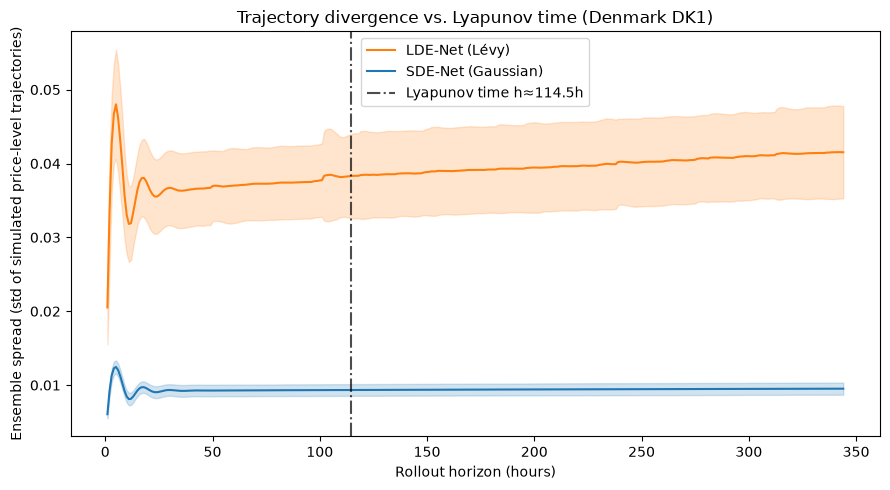


Spread at h/2 (57h):
horizon_hours              57.000000
LDE-Net (Levy) mean         0.036935
LDE-Net (Levy) std          0.005016
SDE-Net (Gaussian) mean     0.009283
SDE-Net (Gaussian) std      0.000781
Name: 56, dtype: float64

Spread at h (114h):
horizon_hours              114.000000
LDE-Net (Levy) mean          0.038290
LDE-Net (Levy) std           0.005625
SDE-Net (Gaussian) mean      0.009342
SDE-Net (Gaussian) std       0.000792
Name: 113, dtype: float64

Spread at 3h (344h):
horizon_hours              344.000000
LDE-Net (Levy) mean          0.041524
LDE-Net (Levy) std           0.006242
SDE-Net (Gaussian) mean      0.009518
SDE-Net (Gaussian) std       0.000822
Name: 343, dtype: float64


In [60]:
# ============================================================
# TRAJECTORY-DIVERGENCE EXPERIMENT (corrected Safe Horizon test)
#
# The previous rollout experiment measured "model's single forecast
# vs. the one real outcome" - but price differences are close to
# stationary noise, so a rolled-out model's guess quickly settles
# near the unconditional mean, making that error flat regardless of
# horizon. This does NOT test what a Lyapunov exponent describes.
#
# Lyapunov divergence is about trajectories separating from each
# other over time. This experiment instead: runs the SAME trained
# model, from the SAME starting window, many times independently
# (each rollout draws its own random Levy/Gaussian shocks, since the
# model already injects stochastic noise at every step). We then
# convert each rolled-out difference-path into a cumulative price-
# LEVEL trajectory, and measure how far these simulated trajectories
# spread apart from each other as a function of horizon - directly
# analogous to Figure panel (a)'s "paths fanning out from a common
# start."
# ============================================================

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

LYAPUNOV_TIME_HOURS = 114.48
ROLLOUT_HORIZON = int(np.ceil(3 * LYAPUNOV_TIME_HOURS))  # 344
N_STARTS = 100
K_ENSEMBLE = 30
SEQ_LEN = 8
SEEDS = [0, 1, 2, 3, 4]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def ensemble_rollout(model, initial_window, k_ensemble, horizon):
    """
    Runs K_ENSEMBLE independent stochastic rollouts from the SAME
    starting window, using the SAME trained model. Each ensemble
    member draws its own random noise at every step (the model's
    forward pass already injects stochastic Levy/Gaussian shocks).
    Returns (k_ensemble, horizon) array of predicted DIFFERENCES.
    """
    windows = initial_window.unsqueeze(0).repeat(k_ensemble, 1).to(device)
    preds = np.zeros((k_ensemble, horizon))
    with torch.no_grad():
        for k in range(horizon):
            _, out = model(windows)
            step_pred = out.mean(dim=1)
            preds[:, k] = step_pred.cpu().numpy()
            windows = torch.cat([windows[:, 1:], step_pred.unsqueeze(1)], dim=1)
    return preds


# ----------------------------------------------------------------
# Starting windows (reuse the same test-set starting points as before)
# ----------------------------------------------------------------
test_series = testing_set_scaled3["closescale"].values.astype(np.float64)
n_test = len(test_series)
valid_start_max = n_test - ROLLOUT_HORIZON
start_indices = np.linspace(SEQ_LEN, valid_start_max - 1, N_STARTS, dtype=int)
initial_windows_np = np.stack([test_series[t0 - SEQ_LEN:t0] for t0 in start_indices])
initial_windows = torch.from_numpy(initial_windows_np).float()

# ----------------------------------------------------------------
# For each model (LDE-Net, Gaussian SDE-Net) and seed, run the
# ensemble ensemble_rollout for every starting point, convert
# differences -> cumulative levels, measure ensemble spread (std
# across the K_ENSEMBLE members) at each horizon step, then average
# that spread across starting points.
# ----------------------------------------------------------------
spread_by_model = {"LDE-Net (Levy)": [], "SDE-Net (Gaussian)": []}

for alpha, name in [(1.5, "LDE-Net (Levy)"), (2.0, "SDE-Net (Gaussian)")]:
    for seed in SEEDS:
        print(f"Training {name} (alpha={alpha}) seed={seed} for divergence test...")
        model = train_one_step_model(x_train1, y_train1, alpha=alpha, seed=seed)

        # spread_per_start: (N_STARTS, ROLLOUT_HORIZON)
        spread_per_start = np.zeros((N_STARTS, ROLLOUT_HORIZON))
        for i, window in enumerate(initial_windows):
            preds = ensemble_rollout(model, window, K_ENSEMBLE, ROLLOUT_HORIZON)  # (K_ENSEMBLE, horizon)
            levels = np.cumsum(preds, axis=1)  # convert differences -> cumulative price level
            spread_per_start[i, :] = np.std(levels, axis=0)  # spread across ensemble at each horizon step

        spread_by_model[name].append(spread_per_start.mean(axis=0))  # average over starting points

# ----------------------------------------------------------------
# Aggregate across seeds and plot
# ----------------------------------------------------------------
k_arr = np.arange(1, ROLLOUT_HORIZON + 1)
divergence_df = pd.DataFrame({
    "horizon_hours": k_arr,
    "LDE-Net (Levy) mean": np.mean(np.stack(spread_by_model["LDE-Net (Levy)"]), axis=0),
    "LDE-Net (Levy) std": np.std(np.stack(spread_by_model["LDE-Net (Levy)"]), axis=0),
    "SDE-Net (Gaussian) mean": np.mean(np.stack(spread_by_model["SDE-Net (Gaussian)"]), axis=0),
    "SDE-Net (Gaussian) std": np.std(np.stack(spread_by_model["SDE-Net (Gaussian)"]), axis=0),
})
divergence_df.to_csv("denmark_dk1_trajectory_divergence.csv", index=False)
print("\nSaved: denmark_dk1_trajectory_divergence.csv")

plt.figure(figsize=(9, 5))
plt.plot(k_arr, divergence_df["LDE-Net (Levy) mean"], label="LDE-Net (Lévy)", color="C1")
plt.fill_between(k_arr,
                  divergence_df["LDE-Net (Levy) mean"] - divergence_df["LDE-Net (Levy) std"],
                  divergence_df["LDE-Net (Levy) mean"] + divergence_df["LDE-Net (Levy) std"],
                  alpha=0.2, color="C1")
plt.plot(k_arr, divergence_df["SDE-Net (Gaussian) mean"], label="SDE-Net (Gaussian)", color="C0")
plt.fill_between(k_arr,
                  divergence_df["SDE-Net (Gaussian) mean"] - divergence_df["SDE-Net (Gaussian) std"],
                  divergence_df["SDE-Net (Gaussian) mean"] + divergence_df["SDE-Net (Gaussian) std"],
                  alpha=0.2, color="C0")
plt.axvline(LYAPUNOV_TIME_HOURS, color="black", linestyle="-.", alpha=0.7,
            label=f"Lyapunov time h≈{LYAPUNOV_TIME_HOURS:.1f}h")
plt.xlabel("Rollout horizon (hours)")
plt.ylabel("Ensemble spread (std of simulated price-level trajectories)")
plt.title("Trajectory divergence vs. Lyapunov time (Denmark DK1)")
plt.legend()
plt.tight_layout()
plt.savefig("denmark_dk1_trajectory_divergence_plot.pdf", dpi=300)
plt.show()

print(f"\nSpread at h/2 (57h):")
print(divergence_df.iloc[56])
print(f"\nSpread at h (114h):")
print(divergence_df.iloc[113])
print(f"\nSpread at 3h (344h):")
print(divergence_df.iloc[-1])

In [53]:
# ============================================================
# MULTI-HORIZON COMPARISON TABLE (Denmark DK1)
# Same model set as the T=1 single-horizon comparison: Zero
# baseline, AR(1), GARCH(1,1), LSTM, Gaussian SDE-Net, LDE-Net.
# Extended across all four horizons (T=1,2,3,4 hours ahead).
# ============================================================

import numpy as np
import pandas as pd
import math
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from scipy.stats import levy_stable
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.tsa.ar_model import AutoReg

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEEDS = [0, 1, 2, 3, 4]

HORIZON_DATA = {
    1: (x_train1, y_train1, x_test1, y_test1),
    2: (x_train2, y_train2, x_test2, y_test2),
    3: (x_train3, y_train3, x_test3, y_test3),
    4: (x_train4, y_train4, x_test4, y_test4),
}


def smape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    return 100 * np.mean(2*np.abs(y_pred-y_true)/(np.abs(y_true)+np.abs(y_pred)+eps))


def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    mse = mean_squared_error(y_true, y_pred)
    return {"MSE": mse, "RMSE": math.sqrt(mse),
            "MAE": mean_absolute_error(y_true, y_pred), "SMAPE": smape(y_true, y_pred)}


def summarise(rows):
    df = pd.DataFrame(rows)
    return {
        "MSE": f"{df['MSE'].mean():.6f} $\\pm$ {df['MSE'].std(ddof=1):.6f}",
        "RMSE": f"{df['RMSE'].mean():.6f} $\\pm$ {df['RMSE'].std(ddof=1):.6f}",
        "MAE": f"{df['MAE'].mean():.6f} $\\pm$ {df['MAE'].std(ddof=1):.6f}",
        "SMAPE": f"{df['SMAPE'].mean():.3f} $\\pm$ {df['SMAPE'].std(ddof=1):.3f}",
    }


class Drift(nn.Module):
    def __init__(self, seq_len):
        super().__init__()
        self.fc = nn.Linear(seq_len, seq_len)
        self.relu = nn.ReLU(inplace=True)
    def forward(self, t, x):
        return self.relu(self.fc(x))


class Diffusion(nn.Module):
    def __init__(self, seq_len):
        super().__init__()
        self.relu = nn.ReLU(inplace=True)
        self.fc1 = nn.Linear(seq_len, 100)
        self.fc2 = nn.Linear(100, 1)
    def forward(self, t, x):
        out = self.relu(self.fc1(x))
        out = self.fc2(out)
        return torch.sigmoid(out)


class SDENetSingle(nn.Module):
    def __init__(self, layer_depth, alpha, seq_len, beta=0.0, levy_scale=0.1):
        super().__init__()
        self.layer_depth = layer_depth
        self.alpha = alpha
        self.beta = beta
        self.levy_scale = levy_scale
        self.seq_len = seq_len
        self.downsampling_layers = nn.Linear(seq_len, seq_len)
        self.drift = Drift(seq_len)
        self.diffusion = Diffusion(seq_len)
        self.deltat = 1. / self.layer_depth
        self.sigma = 0.5

    def forward(self, x, training_diffusion=False):
        out = self.downsampling_layers(x)
        if not training_diffusion:
            t = 0
            diffusion_term = self.sigma * self.diffusion(t, out)
            for i in range(self.layer_depth):
                t = float(i) / self.layer_depth
                noise = torch.from_numpy(
                    levy_stable.rvs(self.alpha, self.beta, size=(x.shape[0], self.seq_len), scale=self.levy_scale)
                ).to(x)
                out = out + self.drift(t, out) * self.deltat \
                    + diffusion_term * (self.deltat ** (1 / self.alpha)) * noise
            Drift_out = self.drift(t, out)
            return Drift_out, out
        else:
            return self.diffusion(0, out.detach())


def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def train_sdenet_predict(x_train, y_train, x_test, alpha, seed, epochs=100, iters=50, layer_depth=6):
    set_seed(seed)
    seq_len = x_train.shape[1]
    model = SDENetSingle(layer_depth=layer_depth, alpha=alpha, seq_len=seq_len).to(device)

    optimizer_F = optim.SGD(
        [{'params': model.downsampling_layers.parameters()}, {'params': model.drift.parameters()}],
        lr=1e-4, momentum=0.9, weight_decay=5e-4
    )
    optimizer_G = optim.SGD(
        [{'params': model.diffusion.parameters()}],
        lr=1e-2, momentum=0.9, weight_decay=5e-4
    )
    criterion_bce = nn.BCELoss()

    Xtr = torch.from_numpy(np.asarray(x_train, dtype=np.float64)).float().to(device)
    ytr = torch.from_numpy(np.asarray(y_train, dtype=np.float64)).float().view(-1, 1).to(device)
    Xte = torch.from_numpy(np.asarray(x_test, dtype=np.float64)).float().to(device)
    real_label, fake_label = 0, 1
    batch_size = Xtr.shape[0]

    model.train()
    for epoch in range(epochs):
        for _ in range(iters):
            optimizer_F.zero_grad()
            drift_out, out = model(Xtr)
            pred = out.mean(dim=1, keepdim=True)
            loss = torch.mean((ytr - pred) ** 2)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                list(model.downsampling_layers.parameters()) + list(model.drift.parameters()),
                max_norm=5.0
            )
            optimizer_F.step()

            label_real = torch.full((batch_size, 1), real_label, device=device, dtype=torch.float32)
            optimizer_G.zero_grad()
            predict_in = model(Xtr, training_diffusion=True)
            loss_in = criterion_bce(predict_in, label_real)
            loss_in.backward()

            label_fake = torch.full((batch_size, 1), fake_label, device=device, dtype=torch.float32)
            inputs_out = 2 * torch.randn(batch_size, seq_len, device=device) + Xtr
            predict_out = model(inputs_out, training_diffusion=True)
            loss_out = criterion_bce(predict_out, label_fake)
            loss_out.backward()
            optimizer_G.step()

    model.eval()
    with torch.no_grad():
        _, out_test = model(Xte)
        return out_test.mean(dim=1).cpu().numpy()


class LSTMRegressor(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])


def run_lstm(x_train, y_train, x_test, seed, epochs=100):
    set_seed(seed)
    Xtr = torch.tensor(x_train, dtype=torch.float32).unsqueeze(-1).to(device)
    ytr = torch.tensor(y_train, dtype=torch.float32).view(-1, 1).to(device)
    Xte = torch.tensor(x_test, dtype=torch.float32).unsqueeze(-1).to(device)
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=min(64, len(Xtr)), shuffle=True)
    model = LSTMRegressor().to(device)
    opt = optim.Adam(model.parameters(), lr=1e-3)
    crit = nn.MSELoss()
    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()
    model.eval()
    with torch.no_grad():
        return model(Xte).cpu().numpy().reshape(-1)


# ----------------------------------------------------------------
# Main loop: for each horizon, run every model
# ----------------------------------------------------------------
all_rows = []

for horizon, (xtr, ytr, xte, yte) in HORIZON_DATA.items():
    xtr = np.asarray(xtr, dtype=np.float64)
    ytr = np.asarray(ytr, dtype=np.float64)
    xte = np.asarray(xte, dtype=np.float64)
    yte = np.asarray(yte, dtype=np.float64)

    print(f"\n===== Horizon T+{horizon} =====")

    # --- Zero baseline ---
    zero_pred = np.full_like(yte, ytr[-1])
    m = evaluate(yte, zero_pred)
    m.update({"Horizon": horizon, "Model": "Zero baseline"}); all_rows.append(m)

    # --- AR(1) ---
    try:
        train_series = training_set_scaled3["closescale"].values.astype(np.float64)
        test_series = testing_set_scaled3["closescale"].values.astype(np.float64)
        ar_model = AutoReg(train_series, lags=1, old_names=False).fit()
        ar_pred_full = ar_model.predict(start=len(train_series), end=len(train_series)+len(test_series)-1)
        n = min(len(ar_pred_full), len(yte))
        m = evaluate(yte[:n], ar_pred_full[:n])
        m.update({"Horizon": horizon, "Model": "AR(1)"}); all_rows.append(m)
    except Exception as e:
        print("[AR(1)] Error:", e)

    # --- GARCH(1,1) ---
    try:
        from arch import arch_model
        train_series = training_set_scaled3["closescale"].values.astype(np.float64) * 100
        test_series = testing_set_scaled3["closescale"].values.astype(np.float64) * 100
        am = arch_model(train_series, mean="Constant", vol="GARCH", p=1, q=1, rescale=False)
        res = am.fit(disp="off")
        fc = res.forecast(horizon=len(test_series))
        garch_pred_full = fc.mean.values[-1, :] / 100
        n = min(len(garch_pred_full), len(yte))
        m = evaluate(yte[:n], garch_pred_full[:n])
        m.update({"Horizon": horizon, "Model": "GARCH(1,1)"}); all_rows.append(m)
    except Exception as e:
        print("[GARCH] Error:", e)

    # --- LSTM (5 seeds) ---
    print(f"  Training LSTM x5 seeds...")
    lstm_preds = [run_lstm(xtr, ytr, xte, seed=s) for s in SEEDS]
    m = summarise([evaluate(yte, p) for p in lstm_preds])
    m.update({"Horizon": horizon, "Model": "LSTM"}); all_rows.append(m)

    # --- Gaussian SDE-Net (5 seeds) ---
    print(f"  Training Gaussian SDE-Net (alpha=2.0) x5 seeds...")
    gauss_preds = [train_sdenet_predict(xtr, ytr, xte, alpha=2.0, seed=s) for s in SEEDS]
    m = summarise([evaluate(yte, p) for p in gauss_preds])
    m.update({"Horizon": horizon, "Model": "Gaussian SDE-Net"}); all_rows.append(m)

    # --- LDE-Net (5 seeds) ---
    print(f"  Training LDE-Net (alpha=1.5) x5 seeds...")
    lde_preds = [train_sdenet_predict(xtr, ytr, xte, alpha=1.5, seed=s) for s in SEEDS]
    m = summarise([evaluate(yte, p) for p in lde_preds])
    m.update({"Horizon": horizon, "Model": "LDE-Net"}); all_rows.append(m)

results_df = pd.DataFrame(all_rows)
results_df = results_df[["Horizon", "Model", "MSE", "RMSE", "MAE", "SMAPE"]]
print("\n===== MULTI-HORIZON COMPARISON (Denmark DK1) =====")
print(results_df.to_string(index=False))
results_df.to_csv("denmark_dk1_multihorizon_comparison.csv", index=False)
print("\nSaved: denmark_dk1_multihorizon_comparison.csv")


===== Horizon T+1 =====
  Training LSTM x5 seeds...
  Training Gaussian SDE-Net (alpha=2.0) x5 seeds...
  Training LDE-Net (alpha=1.5) x5 seeds...

===== Horizon T+2 =====
  Training LSTM x5 seeds...
  Training Gaussian SDE-Net (alpha=2.0) x5 seeds...
  Training LDE-Net (alpha=1.5) x5 seeds...

===== Horizon T+3 =====
  Training LSTM x5 seeds...
  Training Gaussian SDE-Net (alpha=2.0) x5 seeds...
  Training LDE-Net (alpha=1.5) x5 seeds...

===== Horizon T+4 =====
  Training LSTM x5 seeds...
  Training Gaussian SDE-Net (alpha=2.0) x5 seeds...
  Training LDE-Net (alpha=1.5) x5 seeds...

===== MULTI-HORIZON COMPARISON (Denmark DK1) =====
 Horizon            Model                     MSE                    RMSE                     MAE               SMAPE
       1    Zero baseline                0.396225                0.629464                0.497806          161.476256
       1            AR(1)                0.193972                0.440422                0.195313          199.161131
  

In [64]:
torch.use_deterministic_algorithms(True)
torch.set_num_threads(1)

In [149]:
# ============================================================
# CONSOLIDATED EXPERIMENT: single source of truth for both
# Experiment 1 (T=1 one-step comparison) and Experiment 3
# (multi-horizon T=1..4 comparison), including per-seed
# Diebold-Mariano tests at every horizon.
#
# Fixes applied vs. the two previously-divergent scripts:
#   - set_seed now includes random.seed() (was missing in the
#     multi-horizon version)
#   - seq_len is always derived from data shape, never a bare
#     global (this was already fine in the multi-horizon version;
#     kept that way here)
#   - torch.use_deterministic_algorithms(True) and
#     torch.set_num_threads(1) to remove CPU-level nondeterminism
#     as a source of run-to-run divergence
#   - per-seed raw predictions are saved to disk ONCE, so every
#     downstream table/test reads from the same trained models
#     rather than re-executing and risking silent divergence
# ============================================================

import numpy as np
import pandas as pd
import math
import random
import pickle
import time

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from scipy.stats import levy_stable, t as t_dist
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.tsa.ar_model import AutoReg

# --- Determinism settings ---
torch.use_deterministic_algorithms(True)
torch.set_num_threads(1)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEEDS = [0, 1, 2, 3, 4]

HORIZON_DATA = {
    1: (x_train1, y_train1, x_test1, y_test1),
    2: (x_train2, y_train2, x_test2, y_test2),
    3: (x_train3, y_train3, x_test3, y_test3),
    4: (x_train4, y_train4, x_test4, y_test4),
}

PREDICTIONS_FILE = "denmark_dk2_all_predictions.pkl"


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def smape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    return 100 * np.mean(2*np.abs(y_pred-y_true)/(np.abs(y_true)+np.abs(y_pred)+eps))


def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    mse = mean_squared_error(y_true, y_pred)
    return {"MSE": mse, "RMSE": math.sqrt(mse),
            "MAE": mean_absolute_error(y_true, y_pred), "SMAPE": smape(y_true, y_pred)}


def summarise(rows):
    df = pd.DataFrame(rows)
    return {
        "MSE": f"{df['MSE'].mean():.6f} $\\pm$ {df['MSE'].std(ddof=1):.6f}",
        "RMSE": f"{df['RMSE'].mean():.6f} $\\pm$ {df['RMSE'].std(ddof=1):.6f}",
        "MAE": f"{df['MAE'].mean():.6f} $\\pm$ {df['MAE'].std(ddof=1):.6f}",
        "SMAPE": f"{df['SMAPE'].mean():.3f} $\\pm$ {df['SMAPE'].std(ddof=1):.3f}",
    }


def diebold_mariano(e1, e2, h=1, power=2):
    e1 = np.asarray(e1).reshape(-1)
    e2 = np.asarray(e2).reshape(-1)
    d = np.abs(e1)**power - np.abs(e2)**power
    T = len(d)
    d_bar = np.mean(d)
    gamma0 = np.var(d, ddof=0)
    gamma = [gamma0]
    for k in range(1, h):
        gamma.append(np.mean((d[:T-k] - d_bar) * (d[k:] - d_bar)))
    var_d = gamma[0] + 2 * sum(gamma[1:])
    if var_d <= 0:
        return 0.0, 1.0
    dm_stat = d_bar / np.sqrt(var_d / T)
    hln = np.sqrt((T + 1 - 2*h + h*(h-1)/T) / T)
    dm_stat_corrected = dm_stat * hln
    p_value = 2 * (1 - t_dist.cdf(np.abs(dm_stat_corrected), df=T-1))
    return dm_stat_corrected, p_value


class Drift(nn.Module):
    def __init__(self, seq_len):
        super().__init__()
        self.fc = nn.Linear(seq_len, seq_len)
        self.relu = nn.ReLU(inplace=True)
    def forward(self, t, x):
        return self.relu(self.fc(x))


class Diffusion(nn.Module):
    def __init__(self, seq_len):
        super().__init__()
        self.relu = nn.ReLU(inplace=True)
        self.fc1 = nn.Linear(seq_len, 100)
        self.fc2 = nn.Linear(100, 1)
    def forward(self, t, x):
        out = self.relu(self.fc1(x))
        out = self.fc2(out)
        return torch.sigmoid(out)


class SDENetSingle(nn.Module):
    def __init__(self, layer_depth, alpha, seq_len, beta=0.0, levy_scale=0.1):
        super().__init__()
        self.layer_depth = layer_depth
        self.alpha = alpha
        self.beta = beta
        self.levy_scale = levy_scale
        self.seq_len = seq_len
        self.downsampling_layers = nn.Linear(seq_len, seq_len)
        self.drift = Drift(seq_len)
        self.diffusion = Diffusion(seq_len)
        self.deltat = 1. / self.layer_depth
        self.sigma = 0.5

    def forward(self, x, training_diffusion=False):
        out = self.downsampling_layers(x)
        if not training_diffusion:
            t = 0
            diffusion_term = self.sigma * self.diffusion(t, out)
            for i in range(self.layer_depth):
                t = float(i) / self.layer_depth
                noise = torch.from_numpy(
                    levy_stable.rvs(self.alpha, self.beta, size=(x.shape[0], self.seq_len), scale=self.levy_scale)
                ).to(x)
                out = out + self.drift(t, out) * self.deltat \
                    + diffusion_term * (self.deltat ** (1 / self.alpha)) * noise
            Drift_out = self.drift(t, out)
            return Drift_out, out
        else:
            return self.diffusion(0, out.detach())


def train_sdenet_predict(x_train, y_train, x_test, alpha, seed, epochs=100, iters=50, layer_depth=6):
    set_seed(seed)
    seq_len = x_train.shape[1]
    model = SDENetSingle(layer_depth=layer_depth, alpha=alpha, seq_len=seq_len).to(device)

    optimizer_F = optim.SGD(
        [{'params': model.downsampling_layers.parameters()}, {'params': model.drift.parameters()}],
        lr=1e-4, momentum=0.9, weight_decay=5e-4
    )
    optimizer_G = optim.SGD(
        [{'params': model.diffusion.parameters()}],
        lr=1e-2, momentum=0.9, weight_decay=5e-4
    )
    criterion_bce = nn.BCELoss()

    Xtr = torch.from_numpy(np.asarray(x_train, dtype=np.float64)).float().to(device)
    ytr = torch.from_numpy(np.asarray(y_train, dtype=np.float64)).float().view(-1, 1).to(device)
    Xte = torch.from_numpy(np.asarray(x_test, dtype=np.float64)).float().to(device)
    real_label, fake_label = 0, 1
    batch_size = Xtr.shape[0]

    model.train()
    for epoch in range(epochs):
        for _ in range(iters):
            optimizer_F.zero_grad()
            drift_out, out = model(Xtr)
            pred = out.mean(dim=1, keepdim=True)
            loss = torch.mean((ytr - pred) ** 2)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                list(model.downsampling_layers.parameters()) + list(model.drift.parameters()),
                max_norm=5.0
            )
            optimizer_F.step()

            label_real = torch.full((batch_size, 1), real_label, device=device, dtype=torch.float32)
            optimizer_G.zero_grad()
            predict_in = model(Xtr, training_diffusion=True)
            loss_in = criterion_bce(predict_in, label_real)
            loss_in.backward()

            label_fake = torch.full((batch_size, 1), fake_label, device=device, dtype=torch.float32)
            inputs_out = 2 * torch.randn(batch_size, seq_len, device=device) + Xtr
            predict_out = model(inputs_out, training_diffusion=True)
            loss_out = criterion_bce(predict_out, label_fake)
            loss_out.backward()
            optimizer_G.step()

    model.eval()
    with torch.no_grad():
        _, out_test = model(Xte)
        return out_test.mean(dim=1).cpu().numpy()


class LSTMRegressor(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])


def run_lstm(x_train, y_train, x_test, seed, epochs=100):
    set_seed(seed)
    Xtr = torch.tensor(x_train, dtype=torch.float32).unsqueeze(-1).to(device)
    ytr = torch.tensor(y_train, dtype=torch.float32).view(-1, 1).to(device)
    Xte = torch.tensor(x_test, dtype=torch.float32).unsqueeze(-1).to(device)
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=min(64, len(Xtr)), shuffle=True)
    model = LSTMRegressor().to(device)
    opt = optim.Adam(model.parameters(), lr=1e-3)
    crit = nn.MSELoss()
    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()
    model.eval()
    with torch.no_grad():
        return model(Xte).cpu().numpy().reshape(-1)


# ----------------------------------------------------------------
# Main loop: train everything ONCE, save all per-seed predictions
# ----------------------------------------------------------------
all_predictions = {}  # all_predictions[horizon][model_name] = {seed: pred_array} or single array for deterministic models
all_deterministic_preds = {}  # all_deterministic_preds[horizon][model_name] = pred_array (Zero, AR(1), GARCH)

t_start = time.time()

for horizon, (xtr, ytr, xte, yte) in HORIZON_DATA.items():
    xtr = np.asarray(xtr, dtype=np.float64)
    ytr = np.asarray(ytr, dtype=np.float64)
    xte = np.asarray(xte, dtype=np.float64)
    yte = np.asarray(yte, dtype=np.float64)

    print(f"\n===== Horizon T+{horizon} (elapsed {(time.time()-t_start)/60:.1f} min) =====")
    all_predictions[horizon] = {}
    all_deterministic_preds[horizon] = {}

    # --- Zero baseline ---
    zero_pred = np.full_like(yte, ytr[-1])
    all_deterministic_preds[horizon]["Zero baseline"] = zero_pred

    # --- AR(1) ---
    try:
        train_series = training_set_scaled3["closescale"].values.astype(np.float64)
        test_series = testing_set_scaled3["closescale"].values.astype(np.float64)
        ar_model = AutoReg(train_series, lags=1, old_names=False).fit()
        ar_pred_full = ar_model.predict(start=len(train_series), end=len(train_series)+len(test_series)-1)
        n = min(len(ar_pred_full), len(yte))
        all_deterministic_preds[horizon]["AR(1)"] = np.asarray(ar_pred_full[:n])
    except Exception as e:
        print("[AR(1)] Error:", e)

    # --- GARCH(1,1) ---
    try:
        from arch import arch_model
        train_series = training_set_scaled3["closescale"].values.astype(np.float64) * 100
        test_series = testing_set_scaled3["closescale"].values.astype(np.float64) * 100
        am = arch_model(train_series, mean="Constant", vol="GARCH", p=1, q=1, rescale=False)
        res = am.fit(disp="off")
        fc = res.forecast(horizon=len(test_series))
        garch_pred_full = fc.mean.values[-1, :] / 100
        n = min(len(garch_pred_full), len(yte))
        all_deterministic_preds[horizon]["GARCH(1,1)"] = np.asarray(garch_pred_full[:n])
    except Exception as e:
        print("[GARCH] Error:", e)

    # --- LSTM (5 seeds) ---
    print(f"  Training LSTM x5 seeds...")
    all_predictions[horizon]["LSTM"] = {s: run_lstm(xtr, ytr, xte, seed=s) for s in SEEDS}

    # --- Gaussian SDE-Net (5 seeds) ---
    print(f"  Training Gaussian SDE-Net (alpha=2.0) x5 seeds...")
    all_predictions[horizon]["Gaussian SDE-Net"] = {
        s: train_sdenet_predict(xtr, ytr, xte, alpha=2.0, seed=s) for s in SEEDS
    }

    # --- LDE-Net (5 seeds) ---
    print(f"  Training LDE-Net (alpha=1.5) x5 seeds...")
    all_predictions[horizon]["LDE-Net"] = {
        s: train_sdenet_predict(xtr, ytr, xte, alpha=1.5, seed=s) for s in SEEDS
    }

    # Save incrementally after each horizon, in case of interruption
    with open(PREDICTIONS_FILE, "wb") as f:
        pickle.dump({
            "all_predictions": all_predictions,
            "all_deterministic_preds": all_deterministic_preds,
            "y_test_by_horizon": {h: np.asarray(HORIZON_DATA[h][3], dtype=np.float64) for h in HORIZON_DATA if h <= horizon},
        }, f)
    print(f"  Saved progress through horizon {horizon} to {PREDICTIONS_FILE}")

print(f"\nTotal training time: {(time.time()-t_start)/60:.1f} minutes")

# ----------------------------------------------------------------
# Build the multi-horizon table (Experiment 3) from saved predictions
# ----------------------------------------------------------------
all_rows = []
for horizon, (xtr, ytr, xte, yte) in HORIZON_DATA.items():
    yte = np.asarray(yte, dtype=np.float64)
    for name, pred in all_deterministic_preds[horizon].items():
        n = min(len(pred), len(yte))
        m = evaluate(yte[:n], pred[:n])
        m.update({"Horizon": horizon, "Model": name}); all_rows.append(m)
    for name in ["LSTM", "Gaussian SDE-Net", "LDE-Net"]:
        preds_by_seed = all_predictions[horizon][name]
        m = summarise([evaluate(yte, preds_by_seed[s]) for s in SEEDS])
        m.update({"Horizon": horizon, "Model": name}); all_rows.append(m)

results_df = pd.DataFrame(all_rows)[["Horizon", "Model", "MSE", "RMSE", "MAE", "SMAPE"]]
print("\n===== MULTI-HORIZON COMPARISON (Denmark DK1) =====")
print(results_df.to_string(index=False))
results_df.to_csv("denmark_dk2_multihorizon_comparison_v2.csv", index=False)

# ----------------------------------------------------------------
# Per-seed Diebold-Mariano tests at every horizon: LDE-Net vs
# Gaussian SDE-Net, and both vs Zero baseline
# ----------------------------------------------------------------
dm_rows = []
for horizon, (xtr, ytr, xte, yte) in HORIZON_DATA.items():
    yte = np.asarray(yte, dtype=np.float64)
    lde_preds = all_predictions[horizon]["LDE-Net"]
    gauss_preds = all_predictions[horizon]["Gaussian SDE-Net"]
    zero_pred = all_deterministic_preds[horizon]["Zero baseline"]

    for s in SEEDS:
        e_lde = yte - lde_preds[s]
        e_gauss = yte - gauss_preds[s]
        e_zero = yte - zero_pred

        stat, p = diebold_mariano(e_lde, e_gauss, h=1)
        dm_rows.append({"Horizon": horizon, "Seed": s, "Comparison": "LDE vs Gaussian",
                         "DM stat": stat, "p-value": p,
                         "Winner": "LDE" if stat < 0 else "Gaussian"})

        stat, p = diebold_mariano(e_lde, e_zero, h=1)
        dm_rows.append({"Horizon": horizon, "Seed": s, "Comparison": "LDE vs Zero",
                         "DM stat": stat, "p-value": p,
                         "Winner": "LDE" if stat < 0 else "Zero"})

        stat, p = diebold_mariano(e_gauss, e_zero, h=1)
        dm_rows.append({"Horizon": horizon, "Seed": s, "Comparison": "Gaussian vs Zero",
                         "DM stat": stat, "p-value": p,
                         "Winner": "Gaussian" if stat < 0 else "Zero"})

dm_df = pd.DataFrame(dm_rows)
print("\n===== PER-SEED DIEBOLD-MARIANO RESULTS (all horizons) =====")
print(dm_df.to_string(index=False))
dm_df.to_csv("denmark_dk1_dm_tests_all_horizons.csv", index=False)

# Summary: for LDE vs Gaussian specifically, how many seeds favor each, per horizon
print("\n===== LDE vs Gaussian: win-count summary per horizon =====")
for horizon in HORIZON_DATA:
    sub = dm_df[(dm_df["Horizon"] == horizon) & (dm_df["Comparison"] == "LDE vs Gaussian")]
    sig = sub[sub["p-value"] < 0.05]
    lde_wins = (sig["Winner"] == "LDE").sum()
    gauss_wins = (sig["Winner"] == "Gaussian").sum()
    print(f"Horizon {horizon}: {lde_wins} seeds significantly favor LDE, "
          f"{gauss_wins} favor Gaussian, {len(sub)-len(sig)} not significant")

print("\nAll results saved:")
print(f"  - {PREDICTIONS_FILE} (raw per-seed predictions, for future re-analysis)")
print(f"  - denmark_dk1_multihorizon_comparison_v2.csv")
print(f"  - denmark_dk1_dm_tests_all_horizons.csv")


===== Horizon T+1 (elapsed 0.0 min) =====
  Training LSTM x5 seeds...
  Training Gaussian SDE-Net (alpha=2.0) x5 seeds...
  Training LDE-Net (alpha=1.5) x5 seeds...
  Saved progress through horizon 1 to denmark_dk2_all_predictions.pkl

===== Horizon T+2 (elapsed 322.0 min) =====
  Training LSTM x5 seeds...
  Training Gaussian SDE-Net (alpha=2.0) x5 seeds...
  Training LDE-Net (alpha=1.5) x5 seeds...
  Saved progress through horizon 2 to denmark_dk2_all_predictions.pkl

===== Horizon T+3 (elapsed 1144.3 min) =====
  Training LSTM x5 seeds...
  Training Gaussian SDE-Net (alpha=2.0) x5 seeds...
  Training LDE-Net (alpha=1.5) x5 seeds...
  Saved progress through horizon 3 to denmark_dk2_all_predictions.pkl

===== Horizon T+4 (elapsed 1409.9 min) =====
  Training LSTM x5 seeds...
  Training Gaussian SDE-Net (alpha=2.0) x5 seeds...
  Training LDE-Net (alpha=1.5) x5 seeds...
  Saved progress through horizon 4 to denmark_dk2_all_predictions.pkl

Total training time: 1678.7 minutes

===== MULT

In [ ]:
# ============================================================
# EXPERIMENT 2: Sensitivity to the Levy stability parameter alpha
# Denmark DK1, all four horizons (T=1..4), full 5-seed reporting
# (not collapsed to a single point estimate, unlike some published
# comparisons - given we already found seed-dependent direction
# instability in the T=1 LDE-Net-vs-Gaussian comparison, a sweep
# reported as single numbers per cell could not distinguish a real
# alpha-effect from training noise).
#
# COST WARNING: with the default ALPHA_GRID (5 values), 4 horizons,
# and N_SEEDS=5, this runs 100 independent trainings. At ~9 min/run
# (our earlier benchmark), that is roughly 15 hours sequentially.
# Reduce ALPHA_GRID, N_SEEDS, EPOCHS, or ITERS below if you want a
# faster (less complete) first pass.
# ============================================================

import numpy as np
import pandas as pd
import math
import random
import time

import torch
import torch.nn as nn
import torch.optim as optim
from scipy.stats import levy_stable
from sklearn.metrics import mean_squared_error, mean_absolute_error

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ---- Scope knobs: reduce these for a faster/cheaper first pass ----
ALPHA_GRID = [1.2, 1.4, 1.6, 1.8, 2.0]
N_SEEDS = 5
EPOCHS = 100
ITERS = 50
SEEDS = list(range(N_SEEDS))

HORIZON_DATA = {
    1: (x_train1, y_train1, x_test1, y_test1),
    2: (x_train2, y_train2, x_test2, y_test2),
    3: (x_train3, y_train3, x_test3, y_test3),
    4: (x_train4, y_train4, x_test4, y_test4),
}


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class Drift(nn.Module):
    def __init__(self, seq_len):
        super().__init__()
        self.fc = nn.Linear(seq_len, seq_len)
        self.relu = nn.ReLU(inplace=True)
    def forward(self, t, x):
        return self.relu(self.fc(x))


class Diffusion(nn.Module):
    def __init__(self, seq_len):
        super().__init__()
        self.relu = nn.ReLU(inplace=True)
        self.fc1 = nn.Linear(seq_len, 100)
        self.fc2 = nn.Linear(100, 1)
    def forward(self, t, x):
        out = self.relu(self.fc1(x))
        out = self.fc2(out)
        return torch.sigmoid(out)


class SDENetSingle(nn.Module):
    def __init__(self, layer_depth, alpha, seq_len, beta=0.0, levy_scale=0.1):
        super().__init__()
        self.layer_depth = layer_depth
        self.alpha = alpha
        self.beta = beta
        self.levy_scale = levy_scale
        self.seq_len = seq_len
        self.downsampling_layers = nn.Linear(seq_len, seq_len)
        self.drift = Drift(seq_len)
        self.diffusion = Diffusion(seq_len)
        self.deltat = 1. / self.layer_depth
        self.sigma = 0.5

    def forward(self, x, training_diffusion=False):
        out = self.downsampling_layers(x)
        if not training_diffusion:
            t = 0
            diffusion_term = self.sigma * self.diffusion(t, out)
            for i in range(self.layer_depth):
                t = float(i) / self.layer_depth
                noise = torch.from_numpy(
                    levy_stable.rvs(self.alpha, self.beta, size=self.seq_len, scale=self.levy_scale)
                ).to(x)
                out = out + self.drift(t, out) * self.deltat \
                    + diffusion_term * (self.deltat ** (1 / self.alpha)) * noise
            Drift_out = self.drift(t, out)
            return Drift_out, out
        else:
            return self.diffusion(0, out.detach())


def train_single_horizon_sdenet(x_train, y_train, x_test, alpha, seed,
                                 epochs=EPOCHS, iters=ITERS, layer_depth=6):
    """Trains ONE standalone SDE-Net at the given alpha on the given
    horizon's data. Generalised (vs. the T=1-only version) to accept
    per-horizon arrays explicitly, so it can be reused across T=1..4."""
    set_seed(seed)
    seq_len = x_train.shape[1]
    model = SDENetSingle(layer_depth=layer_depth, alpha=alpha, seq_len=seq_len).to(device)

    optimizer_F = optim.SGD(
        [{'params': model.downsampling_layers.parameters()}, {'params': model.drift.parameters()}],
        lr=1e-4, momentum=0.9, weight_decay=5e-4
    )
    optimizer_G = optim.SGD(
        [{'params': model.diffusion.parameters()}],
        lr=1e-2, momentum=0.9, weight_decay=5e-4
    )
    criterion_bce = nn.BCELoss()

    Xtr = torch.from_numpy(np.asarray(x_train, dtype=np.float64)).float().to(device)
    ytr = torch.from_numpy(np.asarray(y_train, dtype=np.float64)).float().view(-1, 1).to(device)
    Xte = torch.from_numpy(np.asarray(x_test, dtype=np.float64)).float().to(device)

    real_label, fake_label = 0, 1
    batch_size = Xtr.shape[0]

    model.train()
    for epoch in range(epochs):
        for _ in range(iters):
            optimizer_F.zero_grad()
            drift_out, out = model(Xtr)
            pred = out.mean(dim=1, keepdim=True)
            loss = torch.mean((ytr - pred) ** 2)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                list(model.downsampling_layers.parameters()) + list(model.drift.parameters()),
                max_norm=5.0
            )
            optimizer_F.step()

            label_real = torch.full((batch_size, 1), real_label, device=device, dtype=torch.float32)
            optimizer_G.zero_grad()
            predict_in = model(Xtr, training_diffusion=True)
            loss_in = criterion_bce(predict_in, label_real)
            loss_in.backward()

            label_fake = torch.full((batch_size, 1), fake_label, device=device, dtype=torch.float32)
            inputs_out = 2 * torch.randn(batch_size, seq_len, device=device) + Xtr
            predict_out = model(inputs_out, training_diffusion=True)
            loss_out = criterion_bce(predict_out, label_fake)
            loss_out.backward()
            optimizer_G.step()

    model.eval()
    with torch.no_grad():
        _, out_test = model(Xte)
        pred_test = out_test.mean(dim=1).cpu().numpy()
    return pred_test


# ----------------------------------------------------------------
# Run the full grid: alpha x horizon x seed
# ----------------------------------------------------------------

results_rows = []
all_preds = {}  # all_preds[(alpha, horizon)][seed] = predictions, for later DM tests

total_runs = len(ALPHA_GRID) * len(HORIZON_DATA) * len(SEEDS)
run_count = 0
t_start = time.time()

for horizon, (xtr, ytr, xte, yte) in HORIZON_DATA.items():
    yte = np.asarray(yte, dtype=np.float64)
    for alpha in ALPHA_GRID:
        preds_by_seed = {}
        mses = []
        for seed in SEEDS:
            run_count += 1
            elapsed = time.time() - t_start
            eta = (elapsed / run_count) * (total_runs - run_count) if run_count > 0 else 0
            print(f"[{run_count}/{total_runs}] horizon=T{horizon} alpha={alpha} seed={seed}  "
                  f"(elapsed {elapsed/60:.1f} min, ETA {eta/60:.1f} min)")

            pred = train_single_horizon_sdenet(xtr, ytr, xte, alpha=alpha, seed=seed)
            preds_by_seed[seed] = pred
            n = min(len(pred), len(yte))
            mses.append(mean_squared_error(yte[:n], pred[:n]))

        all_preds[(alpha, horizon)] = preds_by_seed
        results_rows.append({
            "alpha": alpha,
            "horizon": f"T+{horizon}",
            "MSE_mean": np.mean(mses),
            "MSE_std": np.std(mses, ddof=1),
            "MSE_per_seed": ", ".join(f"{m:.6f}" for m in mses),
        })

results_df = pd.DataFrame(results_rows)
print("\n===== ALPHA SENSITIVITY SWEEP (Denmark DK1) =====")
print(results_df.to_string(index=False))
results_df.to_csv("denmark_dk1_alpha_sensitivity.csv", index=False)
print("\nSaved: denmark_dk1_alpha_sensitivity.csv")

# Pivot to a paper-style table: rows=alpha, columns=horizon, values=mean MSE
pivot_mean = results_df.pivot(index="alpha", columns="horizon", values="MSE_mean")
print("\n--- Mean MSE by alpha x horizon (paper-table style) ---")
print(pivot_mean.to_string())